# Polymarket — the price, the book, and the ladder

Three of the four venues in this directory serve a number between zero and one
and invite you to read it as a probability. This notebook is about why that
reading is wrong on Polymarket specifically, by how much, and in which
direction — and about the one thing this venue has that nothing else in the
stack does: a **term structure over the resolution date** of a conflict, fifteen
monthly rungs deep.

Polymarket is the venue with the conflict and election markets, the deepest
books, and the worst-behaved metadata. It is also the only venue where the
questions this project cares about — ceasefires, leader exits, invasions — exist
at all, because [17 CFR 40.11(a)(1)](https://www.ecfr.gov/current/title-17/chapter-I/part-40/section-40.11)
forbids a CFTC-registered entity from listing a contract that "involves, relates
to, or references terrorism, assassination, war". So the conflict book is
permanently offshore, and a US reader may read it and not trade it. That
separation is fine here, because reading is the whole exercise.

**What this notebook is.** Nine worked measurements, each computed in the cell
above the paragraph that discusses it, on a venue that is being *measured*
rather than traded. Everything is read-only and unauthenticated: no wallet, no
key, no order, nothing that can sign a transaction. Fourteen live reads, paced,
against an on-disk cache; everything else comes from the **72,838 closed
Polymarket markets** already harvested under `data/`.

**What it is not.** It is not advice about a trade, and it does not say whether
any price here is worth taking. Where a number cannot be computed from public
data, the notebook names it rather than estimating it —
`metrics.NOT_COMPUTABLE` is the register, and section 10 prints it.

**Where the facts come from.** The verified research this rests on is
[`sefer/planning/polymarket-event-probabilities.md`](../../../sefer/planning/polymarket-event-probabilities.md),
a five-pass run against the live APIs on 2026-09-26. Its figures are not
re-derived here except where a measurement below is *supposed* to reproduce one,
and then the notebook says so and prints both. The cross-venue comparison —
Polymarket against Kalshi, PredictIt and the Iowa Electronic Markets back to
1988 — is [`calibration.ipynb`](calibration.ipynb) and is deliberately absent
from here. The other venues are [`kalshi.ipynb`](kalshi.ipynb) and
[`predictit_and_iem.ipynb`](predictit_and_iem.ipynb).

In [23]:
%reload_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Anchor on this notebook's own directory rather than on the working directory:
# VS Code can root a notebook at the workspace folder instead of at the file,
# and then a relative "utils/" resolves somewhere else entirely and the imports
# below fail with ModuleNotFoundError.
_here = Path.cwd()
_PM = (_here if (_here / "utils" / "polymarket.py").exists()
       else _here / "notebooks" / "prediction_markets")
for _path in (str(_PM), str(_PM.parents[1])):     # notebooks/prediction_markets, then meida
    if _path not in sys.path:
        sys.path.insert(0, _path)

import json
from collections.abc import Callable
from datetime import date, datetime, timedelta, timezone
from typing import Any

import httpx
import numpy
from matplotlib import pyplot
# Matplotlib accepts a datetime on an axis and converts it with this same
# function; calling it here keeps the type checker's account of the call
# honest, since the stubs type these parameters as floats.
from matplotlib.dates import date2num
from numpy.typing import NDArray

from lib import config
from utils import corpus, metrics as mx, polymarket as pm

pyplot.style.use(config.glyfish_style)

#: The day every live figure below was read, and the day the Treasury curve in
#: section 4 was published for. Printed on each figure so a stale re-run is
#: visible rather than silent.
ASOF = date(2026, 9, 26)

#: The live-read budget. Politeness, not quota, sets the pace here: the
#: reference run sustained 81-155 req/s across three hosts with zero HTTP 429
#: and no rate-limit headers exposed at all, so the constraint is self-imposed.
#: `PolymarketReader` paces per host (Gamma 0.35s, CLOB 0.12s, data-api 0.60s)
#: and caches every response to disk under data/_cache, so a re-execution of
#: this notebook replays from the cache and issues nothing.
BUDGET = 20

READER = pm.PolymarketReader()
LEDGER: list[dict[str, Any]] = []


def read(label: str, call: Callable[[], Any], *, uncached: int = 0) -> Any:
    """One live read, charged to the budget and recorded for the closing ledger.

    `uncached` is for the two raw-header probes in section 3, which deliberately
    bypass the reader's cache because a cached response cannot show a CDN `age`
    header. Everything else is charged by watching the reader's own counters.
    """
    before = (READER.stats.requests, READER.stats.cache_hits)
    out = call()
    LEDGER.append({
        "label": label,
        "requests": READER.stats.requests - before[0] + uncached,
        "cache_hits": READER.stats.cache_hits - before[1],
    })
    return out


def stamp_source(*names: str, figure: Any = None) -> None:
    """Name the reads a figure was drawn from, along its bottom edge."""
    figure = figure or pyplot.gcf()
    figure.subplots_adjust(bottom=max(0.17, 0.13 + 0.032 * len(names)))
    figure.text(0.995, 0.005, "\n".join(names), ha="right", va="bottom",
                fontsize=7, family="monospace", alpha=0.65)


print(f"as of {ASOF}, budget {BUDGET} live reads")
print(f"corpus at {corpus.DATA}")
print(f"http cache at {READER.http_cache}")

as of 2026-09-26, budget 20 live reads
corpus at /Users/troy/Develop/gly.fish/meida/notebooks/prediction_markets/data
http cache at /Users/troy/Develop/gly.fish/meida/notebooks/prediction_markets/data/_cache/polymarket/http


## 1. Three hosts, and what each one is for

Polymarket's read surface is about twenty-five endpoints across **three
hosts**, and the split between them is not cosmetic. Getting it wrong is how
the first survey of this source concluded that resolved markets lose their
history, which is false.

* **`gamma-api.polymarket.com`** — the catalogue. Events, markets, tags,
  series, search. One page of `/events/keyset` returns a hundred complete
  records with `tags[]`, the full `markets[]` array and the resolution prose.
  It is the only host that knows what a market *is*.
* **`clob.polymarket.com`** — the book and the path. `/book`, `/books`,
  `/midpoint`, `/prices-history` and `POST /batch-prices-history`. It is the
  only trustworthy source of depth and the workhorse for backfill.
* **`data-api.polymarket.com/v2`** — outcomes and interest. `/resolutions` is
  the authoritative settled record with a transaction hash behind it; `/oi` is
  open interest. The first survey of this source missed this host entirely,
  and it is the one that decides whether anything else can be trusted.

The census below is the only honest count of the universe: `/events/pagination`
is the one route that returns exact totals, and it returns a nonsense
`totalResults: 2` if you call it with no filter at all, so the reader refuses a
bare call. Two live reads.

In [24]:
HOSTS: dict[str, tuple[str, str]] = {
    pm.GAMMA:  ("catalogue", "events, markets, tags, series, search, resolution prose"),
    pm.CLOB:   ("book + path", "/book, /books, /midpoint, /prices-history, /batch-prices-history"),
    pm.DATA_V2: ("outcome + interest", "/resolutions (authoritative), /oi, /trades, /holders"),
}
for _host, (_role, _routes) in HOSTS.items():
    print(f"{_host:42} {_role:19} pace {pm.PACE[_host]:.2f}s   {_routes}")

# Both calls carry a filter deliberately: a bare /events/pagination returns
# totalResults: 2, which is not a count of anything.
_geo_open = read("census: geopolitics open",
                 lambda: READER.count_events(tag_slug="geopolitics", closed=False))
_geo_ever = read("census: geopolitics closed",
                 lambda: READER.count_events(tag_slug="geopolitics", closed=True))

print(f"\ngeopolitics events, open now      {_geo_open:>10,}")
print(f"geopolitics events, ever closed   {_geo_ever:>10,}   <- the labelled corpus")

_manifest = pm.load_manifest()
print(f"\nharvested on disk, closed only ({_manifest['harvested_at'][:10]}):")
print(f"  events                          {_manifest['events']:>10,}")
print(f"  markets                         {_manifest['markets']:>10,}")
print(f"  markets with a settled outcome  {_manifest['markets_with_settled_outcome']:>10,}")
print(f"  markets with a stored price path{_manifest['price_paths']['markets_with_a_path']:>10,}")
print(f"  daily observations              "
      f"{_manifest['price_paths']['total_daily_observations']:>10,}")
print(f"  geopolitics closed, by census   "
      f"{_manifest['census_closed_events_by_tag']['geopolitics']:>10,}")

https://gamma-api.polymarket.com           catalogue           pace 0.35s   events, markets, tags, series, search, resolution prose
https://clob.polymarket.com                book + path         pace 0.12s   /book, /books, /midpoint, /prices-history, /batch-prices-history
https://data-api.polymarket.com/v2         outcome + interest  pace 0.60s   /resolutions (authoritative), /oi, /trades, /holders

geopolitics events, open now             440
geopolitics events, ever closed        2,112   <- the labelled corpus

harvested on disk, closed only (2026-09-26):
  events                              10,465
  markets                             72,838
  markets with a settled outcome      72,147
  markets with a stored price path    55,233
  daily observations               1,666,418
  geopolitics closed, by census        2,112


## 2. The identifier model, and why `conditionId` is the key

Five identifiers arrive with every market and only some of them are keys.

`conditionId` (`0x` + 64 hex) is the on-chain condition and the join across all
three hosts: Gamma's `conditionId` is `/v2/resolutions?condition=`'s
`condition_id` and `/v2/oi?condition=`'s key. `questionID` is the UMA question.
The two `clobTokenIds` are the price and book keys — element 0 is Yes, element 1
is No, and for a binary market No is `1 − Yes`, which is why the corpus archives
only the Yes side. The numeric `id`s are stable.

**`slug` is editorial.** It is stable in practice and it is not the question.
The pair printed below makes the point without ambiguity: two *different* events
whose slugs differ by one word, `russia-x-ukraine-ceasefire-agreement-by` and
`russia-x-ukraine-ceasefire-by`, asking about the same war on the same two
dates, and pricing them **two to eight cents apart**. The difference is in the
resolution prose, not in the slug, and a catalogue keyed on slug would have
silently merged them.

That second event also carries the worst metadata defect on the platform, and
it carries it while reporting a quarter of a million dollars of resting bids
between them: its two open rungs have a market `endDate` of **2024-11-28**, six hundred
and sixty-seven days in the past. Any "what resolves in the next ninety days"
query drops them; any ladder built on `endDate` collapses them onto one horizon.
One live read returns both events, because a single `/events/keyset` page
carries fifty-five open Ukraine events whole.

In [25]:
_ukraine = read("keyset: tag_slug=ukraine, closed=false",
                lambda: list(READER.iter_events(tag_slug="ukraine", closed=False,
                                                limit=100, max_pages=2)))
CEASEFIRE = {e["id"]: e for e in _ukraine if "ceasefire" in (e.get("slug") or "")}
print(f"{len(_ukraine)} open Ukraine events on one page; "
      f"{len(CEASEFIRE)} of them ceasefire ladders")

LADDER = CEASEFIRE["478472"]        # "...ceasefire agreement by...?", 18 rungs
RIVAL = CEASEFIRE["486199"]         # "...ceasefire by...?", 4 rungs, past-dated

# The identity block of one rung, verbatim, so the join is visible.
_rung = next(m for m in LADDER["markets"] if m["groupItemTitle"] == "December 31")
print(f"\n{'question':22} {_rung['question']}")
print(f"{'event id / slug':22} {LADDER['id']} / {LADDER['slug']}")
print(f"{'market id':22} {_rung['id']}")
print(f"{'conditionId':22} {_rung['conditionId']}")
print(f"{'questionID':22} {_rung['questionID']}")
for _side, _token in zip(json.loads(_rung["outcomes"]), json.loads(_rung["clobTokenIds"])):
    print(f"{'clobTokenIds[' + _side + ']':22} {_token}")
print(f"{'market slug':22} {_rung['slug']}")

print(f"\nTwo events, two slugs, one war -- and the dates they share are not "
      f"priced the same:")
print(f"{'deadline':12}{'agreement-by bid/ask':>24}{'ceasefire-by bid/ask':>24}"
      f"{'gap (mid)':>11}{'endDate':>13}")
_rival_by_label = {m["groupItemTitle"]: m for m in RIVAL["markets"]}
for _m in sorted((m for m in LADDER["markets"] if not m.get("closed")),
                 key=lambda m: str(m.get("endDate"))):
    _other = _rival_by_label.get(_m["groupItemTitle"])
    if _other is None or _other.get("closed"):
        continue
    _a = (_m["bestBid"] + _m["bestAsk"]) / 2
    _b = (_other["bestBid"] + _other["bestAsk"]) / 2
    print(f"{_m['groupItemTitle']:12}"
          f"{_m['bestBid']:>11.3f} /{_m['bestAsk']:>7.3f}"
          f"{_other['bestBid']:>11.3f} /{_other['bestAsk']:>7.3f}"
          f"{100 * (_a - _b):>+10.1f}c"
          f"{str(_other['endDate'])[:10]:>13}")
print(f"\n'ceasefire-by' endDate is {(ASOF - date(2024, 11, 28)).days} days in the past, "
      f"on rungs carrying "
      f"${sum(m.get('liquidityNum') or 0 for m in RIVAL['markets'] if not m.get('closed')):,.0f} "
      f"of reported liquidity.")

55 open Ukraine events on one page; 2 of them ceasefire ladders

question               Russia x Ukraine ceasefire agreement by December 31, 2026?
event id / slug        478472 / russia-x-ukraine-ceasefire-agreement-by
market id              2243897
conditionId            0x5c19f205507ce03ff5f3be08a8090a5969ea6870cc07b902a4ca2e61dfe48fdd
questionID             0xdb66445a548627b84121e5cd2fd0048feae80b268a12f13a731686a658d42a99
clobTokenIds[Yes]      99878393523957043401217108863095556720659532630565063651671026144852955005052
clobTokenIds[No]       69565284411089708271128692790745152090129066525382935764397092493923596997488
market slug            russia-x-ukraine-ceasefire-agreement-by-december-31-2026

Two events, two slugs, one war -- and the dates they share are not priced the same:
deadline        agreement-by bid/ask    ceasefire-by bid/ask  gap (mid)      endDate
October 31        0.060 /  0.080      0.040 /  0.050      +2.5c   2024-11-28
December 31       0.210 /  0.220      0.1

## 3. The traps, printed from the responses that set them

Four of them, and each one is a response header or a parameter value rather
than a documented caveat.

**The deprecated routes still serve.** `/events` and `/markets` answer 200 with
`Deprecation: true`, a `Warning: 299 - "use /events/keyset"` and a `Sunset`
date that has been in the past for nearly five months. Nothing breaks if you
use them; they simply stop at `offset=20000` with a 422 telling you to use
keyset — measured in the research pass rather than here — which is a failure
that arrives in the middle of a backfill rather than at the start of one.

**Gamma is CDN-cached.** `Cache-Control: public, max-age=300` on every
catalogue route, with a Cloudflare `Age` counting up to it. The `outcomePrices`
embedded in an event are therefore **up to five minutes stale**, and section 6
shows them being worse than stale. Gamma is not a live price source; the CLOB
book is.

These two are shown with a raw `httpx` call rather than through the reader,
because the reader caches to disk and a cached response cannot carry a CDN
`Age`. Two live reads, and they are the only uncached ones in the notebook.

In [26]:
def head_probe(url: str, params: dict[str, Any]) -> dict[str, str]:
    """Status and the interesting headers of one uncached GET, discarding the body."""
    with httpx.Client(headers={"User-Agent": pm.USER_AGENT}, timeout=40.0,
                      follow_redirects=True) as client:
        response = client.get(url, params=params)
    wanted = ("deprecation", "sunset", "warning", "cache-control", "age",
              "cf-cache-status", "expires")
    out = {"status": str(response.status_code)}
    out.update({k: response.headers[k] for k in wanted if k in response.headers})
    return out


for _label, _url, _params in (
        ("deprecated /events", f"{pm.GAMMA}/events", {"limit": 1}),
        ("current /events/keyset", f"{pm.GAMMA}/events/keyset",
         {"limit": 1, "tag_slug": "ukraine"})):
    _headers = read(f"headers: {_label}",
                    lambda u=_url, p=_params: head_probe(u, p), uncached=1)
    print(f"{_label}")
    for _key, _value in _headers.items():
        print(f"    {_key:17} {_value[:70]}")

deprecated /events
    status            200
    deprecation       true
    sunset            Fri, 01 May 2026 00:00:00 GMT
    warning           299 - "use /events/keyset"
    cache-control     public, max-age=300
    age               239
    cf-cache-status   HIT
    expires           Sun, 27 Sep 2026 00:55:33 GMT
current /events/keyset
    status            200
    cache-control     public, max-age=300
    cf-cache-status   EXPIRED
    expires           Sun, 27 Sep 2026 00:55:33 GMT


**The fidelity cliff, which is the one that produced a wrong conclusion about
this source.** `GET /prices-history` on a *resolved* market returns
`{"history": []}` with HTTP 200 unless `fidelity` is at least **720** minutes.
Call it without a `fidelity` and a market that has a complete, permanent price
path looks like a market that lost its history on settlement. The flip is sharp
and there is no error, no warning and no empty-response code to notice.

Below, the same resolved rung at four settings. Note the spacings: at
`fidelity=720` the returned points are spaced **twelve and twenty-four hours**,
not twelve minutes — `resolution_seconds` echoes the request rather than the
delivery, so a point count never tells you the granularity you got. Twelve-hour
buckets are permanent, verified elsewhere back to January 2024; three-hour
buckets exist only for roughly the trailing two months and the docs are wrong
to call them permanent. `pm.DAILY_FIDELITY` is pinned at 1440 for exactly this
reason. Four live reads.

In [27]:
_closed_rung = min((m for m in LADDER["markets"] if m.get("closed")),
                   key=lambda m: str(m.get("endDate")))
_token = json.loads(_closed_rung["clobTokenIds"])[0]
print(f"{_closed_rung['question']}   closedTime {_closed_rung['closedTime']}\n")
print(f"{'fidelity (min)':16}{'points':>8}  {'first':11} {'last':11}  "
      f"{'distinct spacings (hours)':30} last p")
for _fidelity in (719, 720, 1440, None):
    _params = {"market": _token, "interval": "max"}
    if _fidelity is not None:
        _params["fidelity"] = _fidelity
    _payload = read(f"prices-history fidelity={_fidelity}",
                    lambda p=_params: READER.get(f"{pm.CLOB}/prices-history", params=p))
    _history = (_payload or {}).get("history") or []
    _label = "omitted" if _fidelity is None else str(_fidelity)
    if not _history:
        print(f"{_label:16}{0:>8}  {'-':11} {'-':11}  "
              f"{'HTTP 200 with an empty history':30} -")
        continue
    _spacings = sorted({round((_history[i + 1]["t"] - _history[i]["t"]) / 3600, 1)
                        for i in range(len(_history) - 1)})
    _first = datetime.fromtimestamp(_history[0]["t"], timezone.utc)
    _last = datetime.fromtimestamp(_history[-1]["t"], timezone.utc)
    print(f"{_label:16}{len(_history):>8}  {_first:%Y-%m-%d}  {_last:%Y-%m-%d}   "
          f"{str(_spacings):30} {_history[-1]['p']}")

print(f"\npm.DAILY_FIDELITY = {pm.DAILY_FIDELITY}; the corpus on disk was harvested at "
      f"{_manifest['price_paths']['fidelity_minutes']} "
      f"({_manifest['price_paths']['delivered_grain']})")

Russia x Ukraine ceasefire agreement by May 31, 2026?   closedTime 2026-06-01 12:15:34+00

fidelity (min)    points  first       last         distinct spacings (hours)      last p
719                    0  -           -            HTTP 200 with an empty history -
720                   38  2026-05-13  2026-06-01   [12.0, 24.0]                   0.0005
1440                  19  2026-05-14  2026-06-01   [24.0]                         0.0005
omitted                0  -           -            HTTP 200 with an empty history -

pm.DAILY_FIDELITY = 1440; the corpus on disk was harvested at 1440 (one print per day, in the 00:00 UTC hour (measured))


## 4. A price is not a probability, and the wedges are measurable

A Polymarket price is a risk-neutral, fee-distorted, capital-locked,
oracle-conditional quote on whether credible reporting will converge on X by a
date. Four wedges separate it from a probability, they point in different
directions, and on this ladder two of them are exactly zero — which is worth
establishing by reading the fields rather than by assuming.

**Fees.** `fee = shares × rate × p × (1−p)` with `rate = 0.04`, taker only, and
it applies to markets whose `feeType` is `"politics_fees"`. Every rung here
reports `feeType: None` and `feesEnabled: False`: geopolitics on this venue is
genuinely fee-free, so the fee-implied no-arbitrage band `2·rate·p(1−p)` is
zero and the binding band is the observed spread instead.

**The time value of collateral, which is the wedge that matters at range.**
Polymarket's collateral is pUSD, an ERC-20 wrapper on USDC, and it pays the
holder nothing. A claim that settles in τ years is therefore worth about
`p·exp(−rτ)` to someone who could otherwise hold Treasuries, so the *price* sits
below the probability by the discount, and by more the further out you go. The
anchor is the par curve published for 2026-09-25 — 3-month 4.24%, 1-year 4.50%,
2-year 4.81%, 3-year 4.94% — interpolated on each rung's own horizon.
Polymarket offsets this on a curated set flagged `holdingRewardsEnabled`,
which pays an annualized rate on the mid-price value of a position — 555 markets
carried the flag when the research pass counted them, and they are largely this
project's markets. None of these fifteen rungs is flagged, so the correction
applies in full.

**Longshot bias**, measured on this venue's own closed corpus in section 9, and
applied here as the conventional haircut below ten cents.

The table below applies all of it. The last column is the one to read: at the
front of the ladder the longshot haircut is the larger correction and the
discount is a rounding error at three hundredths of a cent; on the last rung
the discount correction is **four times the bid-ask spread**, and it exceeds the
spread on every rung beyond April 2027 except the two whose spread has widened
to three and four cents. A reader who worries about the spread and not about the
discount has the two costs the wrong way round at exactly the horizons this
venue is interesting for.

In [28]:
#: US Treasury par yields, published for 2026-09-25 and verified in the research
#: pass. Anchoring `r` on the curve rather than on a constant is deliberate: the
#: one paper that measures the settlement discount directly has magnitude
#: constants its own abstract does not support, so the curve is the defensible
#: input and the paper's usable finding is the *shape* -- a discount adjustment
#: removes 48-88% of the apparent long-horizon miscalibration gradient.
TREASURY: tuple[tuple[float, float], ...] = (
    (0.25, 0.0424), (1.0, 0.0450), (2.0, 0.0481), (3.0, 0.0494))


def treasury_rate(years: float) -> float:
    """The par yield at `years`, linearly interpolated and flat outside the curve."""
    return float(numpy.interp(years, [y for y, _ in TREASURY],
                              [r for _, r in TREASURY]))


OPEN_RUNGS = sorted((m for m in LADDER["markets"] if not m.get("closed")),
                    key=lambda m: str(m.get("endDate")))
print(f"{len(OPEN_RUNGS)} open rungs; feeType "
      f"{sorted({str(m.get('feeType')) for m in OPEN_RUNGS})}, "
      f"feesEnabled {sorted({bool(m.get('feesEnabled')) for m in OPEN_RUNGS})}, "
      f"holdingRewardsEnabled {sorted({bool(m.get('holdingRewardsEnabled')) for m in OPEN_RUNGS})}, "
      f"tick {sorted({m.get('orderPriceMinTickSize') for m in OPEN_RUNGS})}")
print(f"fee-implied no-arbitrage band at p=0.5, fee-free: "
      f"{mx.no_arbitrage_band(0.5, taker_rate=0.0):.4f}; "
      f"under politics fees: {mx.no_arbitrage_band(0.5, taker_rate=0.04):.4f}")

print(f"\n{'rung':20}{'days':>6}{'r':>7}{'exp(-rt)':>10}{'mid':>8}{'p^ disc':>9}"
      f"{'disc':>8}{'longshot':>10}{'spread':>8}{'disc/spread':>12}")
for _m in OPEN_RUNGS:
    _horizon = date.fromisoformat(str(_m["endDate"])[:10])
    _days = (_horizon - ASOF).days
    _years = max(0.0, _days / 365.25)
    _rate = treasury_rate(_years)
    _factor = mx.discount_factor(_years, _rate)
    _mid = (_m["bestBid"] + _m["bestAsk"]) / 2
    _discounted = mx.discount_adjust(_mid, _years, _rate)
    _longshot = mx.longshot_adjust(_mid)
    _spread = _m["bestAsk"] - _m["bestBid"]
    print(f"{(_m['groupItemTitle'] or '')[:20]:20}{_days:>6}{100 * _rate:>6.2f}%"
          f"{_factor:>10.4f}{_mid:>8.3f}{_discounted:>9.3f}"
          f"{100 * (_discounted - _mid):>+7.2f}c"
          f"{100 * (_longshot - _mid):>+9.2f}c"
          f"{100 * _spread:>7.1f}c"
          f"{(_discounted - _mid) / _spread:>12.2f}")

15 open rungs; feeType ['None'], feesEnabled [False], holdingRewardsEnabled [False], tick [0.01]
fee-implied no-arbitrage band at p=0.5, fee-free: 0.0000; under politics fees: 0.0200

rung                  days      r  exp(-rt)     mid  p^ disc    disc  longshot  spread disc/spread
October 31              36  4.24%    0.9958   0.070    0.070  +0.03c    -1.40c    2.0c        0.01
November 30             66  4.24%    0.9924   0.115    0.116  +0.09c    +0.00c    1.0c        0.09
December 31             97  4.25%    0.9888   0.215    0.217  +0.24c    +0.00c    1.0c        0.24
January 31, 2027       128  4.27%    0.9851   0.295    0.299  +0.45c    +0.00c    1.0c        0.45
February 28, 2027      156  4.30%    0.9818   0.315    0.321  +0.58c    +0.00c    1.0c        0.58
March 31, 2027         187  4.33%    0.9781   0.385    0.394  +0.86c    +0.00c    1.0c        0.86
April 30, 2027         217  4.36%    0.9744   0.435    0.446  +1.14c    +0.00c    1.0c        1.14
May 31, 2027           2

## 5. A worked quality read on one market

The rung with the deepest book on the ladder, read from the book rather than
from the fields that claim to describe it. One `POST /books` returns all thirty
tokens — Yes and No for every open rung — in a single round trip, and one
`/v2/oi` returns all fifteen conditions. Two live reads for the whole ladder.

Four things are being separated here.

**Depth is not the touch.** `bestBid`/`bestAsk` say what one share costs, and
the touch on this rung is 222 shares — **forty-seven dollars**. Everything
resting within a cent of it is $891 on the bid and $965 on the ask. The sweep is
the honest version of the same question, and it is worse than either: ten
thousand dollars of asks *can* be bought here, because the book has
seventy-six levels, but only by walking the price from a 0.215 mid to a
volume-weighted **0.368 — seventy-one per cent of slippage**.

**`liquidityNum` is not depth, and the decomposition is exact.** It is the total
resting-*bid* notional summed across **both** outcome books. The check below
reproduces it to four significant figures on every rung from the books
themselves. Because the No side of a cheap outcome is bid near a dollar, that
side dominates: the front rung reports seventy thousand dollars of "liquidity",
of which **ninety-six per cent is bids on the No token** — the side you are not
taking if you think the ceasefire might happen. By the 2027 rungs, priced above
fifty cents, the composition has flipped and the Yes book supplies almost all of
it.

**Volume is not interest.** The event reports eight million dollars of volume
against seven hundred thousand of open interest. Per rung the ratio ranges from
1.1× to 27×.

**The relative spread is the one that binds.** The absolute spread is one cent
on most rungs, which sounds like nothing; against a seven-cent price it is
twenty-nine per cent.

In [29]:
def clob_books(token_ids: list[str]) -> dict[str, mx.OrderBook]:
    """Every book in one round trip, keyed by `asset_id` (the CLOB token id).

    `POST /books` takes a list of `{"token_id": ...}` and returns one book per
    token, so thirty books cost one request instead of thirty. The response is
    keyed off the payload rather than off input order.
    """
    payload = READER.request("POST", f"{pm.CLOB}/books",
                             json_body=[{"token_id": t} for t in token_ids])
    return {row["asset_id"]: mx.OrderBook.from_clob(row) for row in payload}


TOKENS = {m["id"]: json.loads(m["clobTokenIds"]) for m in OPEN_RUNGS}
BOOKS = read("POST /books, 30 tokens",
             lambda: clob_books([t for m in OPEN_RUNGS for t in TOKENS[m["id"]]]))
_oi_rows = read("/v2/oi, 15 conditions",
                lambda: READER.open_interest([m["conditionId"] for m in OPEN_RUNGS]))
OI = {row["condition_id"]: float(row["value"]) for row in _oi_rows}
print(f"{len(BOOKS)} books, {len(OI)} open-interest rows")

FOCUS = next(m for m in OPEN_RUNGS if m["groupItemTitle"] == "December 31")
_yes, _no = TOKENS[FOCUS["id"]]
_book = BOOKS[_yes]
_profile = mx.depth_profile(_book)

print(f"\n{FOCUS['question']}")
print(f"  market {FOCUS['id']}  conditionId {FOCUS['conditionId'][:14]}...  "
      f"created {str(FOCUS['createdAt'])[:10]}  endDate {str(FOCUS['endDate'])[:10]}")


def level_cells(level: mx.BookLevel | None) -> str:
    """One book level as three fixed-width columns, or dashes where there is none."""
    if level is None:
        return f"{'-':>9}{'-':>12}{'-':>12}"
    return f"{level.price:>9.3f}{level.size:>12,.0f}{level.notional:>12,.0f}"


print(f"\n  the Yes book, five levels each side:")
print(f"    {'bid':>9}{'size':>12}{'notional':>12}     {'ask':>9}{'size':>12}{'notional':>12}")
for _i in range(5):
    _b = _book.bids[_i] if _i < len(_book.bids) else None
    _a = _book.asks[_i] if _i < len(_book.asks) else None
    print(f"    {level_cells(_b)}     {level_cells(_a)}")

print(f"\n  touch                       {_profile['best_bid']:.3f} / {_profile['best_ask']:.3f}"
      f"   ({_profile['n_bid_levels']} bid levels, {_profile['n_ask_levels']} ask)")
print(f"  absolute spread             {100 * _profile['absolute_spread']:.1f}c")
print(f"  relative spread             {100 * _profile['relative_spread']:.1f}%")
print(f"  depth within 1c, bid        ${_profile['bid_1c']:>12,.0f}")
print(f"  depth within 1c, ask        ${_profile['ask_1c']:>12,.0f}")
print(f"  depth within 5c, bid / ask  ${_profile['bid_5c']:>12,.0f}  /  ${_profile['ask_5c']:,.0f}")
print(f"  book imbalance at 1c        {mx.book_imbalance(_book):+.3f}")
_sweep = mx.sweep_cost(_book, "ask", 10_000)
print(f"  buying $10,000 of asks      filled ${_sweep['filled']:,.0f} of it at a vwap of "
      f"{_sweep['vwap']:.4f}, {100 * _sweep['relative_slippage']:.2f}% slippage on the mid, "
      f"${_sweep['unfilled']:,.0f} unfilled")

_yes_bids = sum(level.notional for level in _book.bids)
_no_bids = sum(level.notional for level in BOOKS[_no].bids)
print(f"\n  liquidityNum, as reported   ${FOCUS['liquidityNum']:>12,.0f}")
print(f"  resting bid notional, Yes   ${_yes_bids:>12,.0f}")
print(f"  resting bid notional, No    ${_no_bids:>12,.0f}")
print(f"  their sum                   ${_yes_bids + _no_bids:>12,.0f}"
      f"   ratio to liquidityNum {FOCUS['liquidityNum'] / (_yes_bids + _no_bids):.4f}")
print(f"  Gamma's own `spread` field  {FOCUS['spread']}"
      f"   (a book-derived spread of {_profile['absolute_spread']:.3f})")

print(f"\n  volumeNum                   ${FOCUS['volumeNum']:>12,.0f}")
print(f"  open interest (/v2/oi)      ${OI[FOCUS['conditionId']]:>12,.0f}")
print(f"  turnover                    "
      f"{mx.volume_to_open_interest(FOCUS['volumeNum'], OI[FOCUS['conditionId']]):>12.1f}x")
print(f"  event volume / OI           ${LADDER['volume']:,.0f} / ${LADDER['openInterest']:,.0f}"
      f"  = {LADDER['volume'] / LADDER['openInterest']:.1f}x")

30 books, 15 open-interest rows

Russia x Ukraine ceasefire agreement by December 31, 2026?
  market 2243897  conditionId 0x5c19f205507c...  created 2026-05-12  endDate 2027-01-01

  the Yes book, five levels each side:
          bid        size    notional           ask        size    notional
        0.210         222          47         0.220         202          44
        0.200       4,222         844         0.230       4,004         921
        0.190       4,414         839         0.240       2,065         496
        0.180       5,731       1,032         0.250       2,536         634
        0.170       1,745         297         0.260         696         181

  touch                       0.210 / 0.220   (21 bid levels, 76 ask)
  absolute spread             1.0c
  relative spread             4.7%
  depth within 1c, bid        $         891
  depth within 1c, ask        $         965
  depth within 5c, bid / ask  $       3,219  /  $2,548
  book imbalance at 1c        -0.040
  b

The same read across all fifteen rungs. Two columns deserve the attention.

`liq/(Y+N)` is the `liquidityNum` decomposition, and it is **0.994 to 1.000 on
every rung** — the field is exactly what it was reverse-engineered to be, and
it is exactly not what its name suggests. Where the Yes price is low the No
column dominates; by the 2027 rungs, priced above fifty cents, the Yes column
dominates instead. The field's composition flips along the ladder, which is why
ranking markets by it produces nonsense.

`dep1c bid` is executable notional within a cent of the touch on the Yes bid,
and it runs **$90 to $1,326**. The research pass measured $88 to $1,215 across
this ladder a few hours earlier; the drift is the market, not a disagreement.
Against the $10,000 depth floor that a trading filter would use, **nothing on
this ladder passes on either side**, and that is the finding that section 7
turns into a statement about what the ladder's shape can and cannot mean.

In [30]:
print(f"{'rung':20}{'bid':>6}{'ask':>6}{'rel sp':>8}{'dep1c bid':>11}{'dep1c ask':>11}"
      f"{'Y bids':>10}{'N bids':>10}{'liqNum':>10}{'liq/(Y+N)':>11}"
      f"{'volume':>11}{'OI':>10}{'turn':>7}")
LADDER_ROWS: list[dict[str, Any]] = []
for _m in OPEN_RUNGS:
    _y, _n = TOKENS[_m["id"]]
    _yb, _nb = BOOKS[_y], BOOKS[_n]
    _row = {
        "market": _m,
        "label": _m["groupItemTitle"],
        "horizon": date.fromisoformat(str(_m["endDate"])[:10]),
        "bid": float(_m["bestBid"]), "ask": float(_m["bestAsk"]),
        "dep_bid": mx.depth_within(_yb, "bid", 0.01),
        "dep_ask": mx.depth_within(_yb, "ask", 0.01),
        # Shares rather than dollars, because an interval position in section 7
        # is share-for-share across two rungs and the binding constraint is size.
        "sh_bid": sum(l.size for l in _yb.bids
                      if l.price >= _yb.bids[0].price - 0.01 - 1e-12),
        "sh_ask": sum(l.size for l in _yb.asks
                      if l.price <= _yb.asks[0].price + 0.01 + 1e-12),
        "yes_bids": sum(l.notional for l in _yb.bids),
        "no_bids": sum(l.notional for l in _nb.bids),
        "liq": float(_m["liquidityNum"] or 0.0),
        "volume": float(_m["volumeNum"] or 0.0),
        "oi": OI.get(_m["conditionId"], float("nan")),
        "created": str(_m["createdAt"])[:10],
    }
    _row["mid"] = (_row["bid"] + _row["ask"]) / 2
    _row["rel_spread"] = mx.relative_spread(_yb)
    LADDER_ROWS.append(_row)
    print(f"{_row['label'][:20]:20}{_row['bid']:>6.2f}{_row['ask']:>6.2f}"
          f"{100 * _row['rel_spread']:>7.1f}%"
          f"{_row['dep_bid']:>11,.0f}{_row['dep_ask']:>11,.0f}"
          f"{_row['yes_bids']:>10,.0f}{_row['no_bids']:>10,.0f}{_row['liq']:>10,.0f}"
          f"{_row['liq'] / (_row['yes_bids'] + _row['no_bids']):>11.4f}"
          f"{_row['volume']:>11,.0f}{_row['oi']:>10,.0f}"
          f"{_row['volume'] / _row['oi']:>7.1f}")

_dep = numpy.array([r["dep_bid"] for r in LADDER_ROWS] + [r["dep_ask"] for r in LADDER_ROWS])
print(f"\ndepth within 1c across 30 sides: min ${_dep.min():,.0f}, median "
      f"${numpy.median(_dep):,.0f}, max ${_dep.max():,.0f}; "
      f"{int((_dep >= 10_000).sum())} of {_dep.size} clear the $10,000 floor")

rung                   bid   ask  rel sp  dep1c bid  dep1c ask    Y bids    N bids    liqNum  liq/(Y+N)     volume        OI   turn
October 31            0.06  0.08   28.6%        615        480     3,269    67,769    70,614     0.9940  1,738,779   284,887    6.1
November 30           0.11  0.12    8.7%        554        532     2,868    34,970    37,837     1.0000     16,127    11,239    1.4
December 31           0.21  0.22    4.7%        891        965    44,924    54,935    99,859     1.0000  2,685,293   269,009   10.0
January 31, 2027      0.29  0.30    3.4%        767        853    36,900     6,277    43,177     1.0000     38,187    20,312    1.9
February 28, 2027     0.31  0.32    3.2%        186      1,426    27,318     4,582    31,899     1.0000      7,114     4,359    1.6
March 31, 2027        0.38  0.39    2.6%        335        467    53,544    17,496    71,041     1.0000    166,212    23,623    7.0
April 30, 2027        0.43  0.44    2.3%         90        123    26,573    

## 6. Volume is not interest, and the liquidity fields lie

The ladder above makes the point quietly. *Democratic Presidential Nominee
2028* makes it impossible to miss, and one live read gets the whole event.

It reports **$1.29 billion of volume against $9.7 million of open interest** —
a hundred and thirty-two times turnover on a market two years from resolution —
and the volume is not where a reader would look for it. The outcomes with the
most reported volume are priced at **five hundredths of a cent** and several of
them have **no bid at all** while reporting two to three million dollars of
`liquidityNum`, which is six times what the actual front-runner reports. The
dead outcomes cluster tightly at forty to fifty-five million dollars of volume
each, which is the signature of a programmatic process rather than of forty-odd
traders forming a view about 2028. **Eighty-eight of the event's 128 outcomes
have no bid at all**, and together they report thirty-three million dollars of
`liquidityNum` — the largest single one being eight times what the actual
front-runner reports.

`outcomePrices` is the field a naive catalogue would key on, and the print
below counts how many of the event's markets even carry it. Fields on this API
are **omitted rather than nulled**, so a loader that assumes the key exists
fails on a quarter of the rows.

Two conclusions, and they are not the same conclusion. `liquidityNum`,
`spread` and `outcomePrices` are *wrong*, in the sense that they describe
something other than what their names say, and no filter should ever use them.
`volume` is *uninterpretable* rather than wrong — it is a real number nobody can
apportion, since `volumeClob` equals `volumeNum` exactly at every percentile and
there is no cross-check inside the API. Section 10 finds that it still separates
calibrated markets from miscalibrated ones anyway, which is a genuinely awkward
result and is reported rather than resolved.

In [31]:
NOMINEE = read("/events/slug/democratic-presidential-nominee-2028",
               lambda: READER.event_by_slug("democratic-presidential-nominee-2028"))
_ms = sorted(NOMINEE["markets"], key=lambda m: -(m.get("volumeNum") or 0.0))


def outcome_price(market: dict) -> float | None:
    """The Yes leg of `outcomePrices`, which is a JSON *string* and often absent."""
    raw = market.get("outcomePrices")
    if not raw:
        return None
    try:
        return float(json.loads(raw)[0])
    except (ValueError, IndexError, TypeError):
        return None


print(f"{NOMINEE['title']}  (event {NOMINEE['id']}, {len(_ms)} outcomes)")
print(f"  volume        ${NOMINEE['volume']:>16,.0f}")
print(f"  open interest ${NOMINEE['openInterest']:>16,.0f}")
print(f"  turnover      {NOMINEE['volume'] / NOMINEE['openInterest']:>17,.1f}x")
print(f"  outcomePrices present on {sum(1 for m in _ms if outcome_price(m) is not None)}"
      f" of {len(_ms)} markets")

print(f"\n  the ten highest-volume outcomes:")
print(f"    {'outcome':22}{'price':>9}{'bid':>8}{'ask':>8}{'volume':>14}"
      f"{'liquidityNum':>14}{'vol24hr':>10}")
for _m in _ms[:10]:
    _p = outcome_price(_m)
    _price = "-" if _p is None else format(_p, ".4f")
    _bid = "none" if not _m.get("bestBid") else format(float(_m["bestBid"]), ".3f")
    _ask = "-" if _m.get("bestAsk") is None else format(float(_m["bestAsk"]), ".3f")
    print(f"    {(_m.get('groupItemTitle') or '')[:22]:22}{_price:>9}{_bid:>8}{_ask:>8}"
          f"{(_m.get('volumeNum') or 0):>14,.0f}{(_m.get('liquidityNum') or 0):>14,.0f}"
          f"{(_m.get('volume24hr') or 0):>10,.0f}")

print()
_total = sum(m.get("volumeNum") or 0.0 for m in _ms)
for _cut in (0.02, 0.01):
    _share = sum(m.get("volumeNum") or 0.0 for m in _ms
                 if (outcome_price(m) or 1.0) < _cut)
    print(f"  share of event volume in outcomes priced under {100 * _cut:.0f}c: "
          f"{100 * _share / _total:.1f}%")
_nobid = [m for m in _ms if not m.get("bestBid")]
print(f"  outcomes with no bid at all: {len(_nobid)} of {len(_ms)}, together reporting "
      f"${sum(m.get('liquidityNum') or 0 for m in _nobid):,.0f} of liquidityNum")
print(f"  the largest single no-bid liquidityNum: "
      f"${max((m.get('liquidityNum') or 0) for m in _nobid):,.0f}")
_front = max(_ms, key=lambda m: outcome_price(m) or 0.0)
print(f"  the front-runner, {_front['groupItemTitle']}, at price "
      f"{outcome_price(_front):.4f}, reports ${_front['liquidityNum']:,.0f}")

Democratic Presidential Nominee 2028  (event 30829, 128 outcomes)
  volume        $   1,285,509,985
  open interest $       9,709,652
  turnover                  132.4x
  outcomePrices present on 53 of 128 markets

  the ten highest-volume outcomes:
    outcome                   price     bid     ask        volume  liquidityNum   vol24hr
    Oprah Winfrey            0.0005    none   0.001    54,420,423     2,884,392       109
    Bernie Sanders           0.0045   0.004   0.005    52,751,863       905,177       114
    Chelsea Clinton          0.0065   0.006   0.007    50,604,031       528,821       135
    Andrew Yang              0.0005    none   0.001    48,828,205     2,625,672       683
    Hunter Biden             0.0050   0.004   0.006    44,502,082     1,155,885       460
    Hillary Clinton          0.0025   0.002   0.003    44,065,824     2,686,252       817
    LeBron James             0.0005    none   0.001    43,986,277     2,893,247         1
    Tim Walz                 0

## 7. The ladder is a distribution

This is the part of the venue that is worth the trouble, and it is not a single
price at all.

A row of *"X happens by date T"* markets is a **cumulative distribution function
over the resolution date**. Each price is `P(resolve ≤ T)` directly, so adjacent
rungs difference into the probability mass falling in each interval — exactly as
an option strike ladder differences into a density over price. That changes what
can be asked of it. A single market can only be judged against its own outcome,
once. A ladder can be judged *internally*, today, on properties that must hold
whatever happens: the CDF must be non-decreasing in T, every interval mass must
be non-negative, the implied hazards must be a plausible shape, and the whole
thing must not offer an arbitrage after the spread.

The Russia–Ukraine ceasefire ladder is the only multi-year conflict term
structure on the platform: **fifteen open monthly rungs from October 2026 to
December 2027**, every one two-sided. Below, it is built with
`metrics.rungs_from_markets` and scored with `metrics.ladder_report`, which
applies the section-4 discount correction first — mandatory, because the rungs
settle at fifteen different dates and differencing raw prices mixes the discount
gradient into the interval mass, biasing every mass downward and capable of
manufacturing a negative one out of a perfectly coherent ladder.

One construction trap first, printed rather than described. `rungs_from_markets`
prefers the market's `endDate` and falls back to parsing the title only when the
date is *implausible* — which it defines as outside 2000–2100. The rival
`russia-x-ukraine-ceasefire-by` event's `endDate` of 2024-11-28 is inside that
range, so the fallback does not fire and its two open rungs land on **the same
horizon**, six hundred and sixty-seven days in the past. A ladder built without
checking the deadlines it was given is not a distribution over anything.

In [32]:
def build_rungs(markets: list[dict]) -> list[mx.Rung]:
    """A ladder from Gamma records, priced at the touch mid.

    `price_key` names a field no Polymarket record carries, which makes the
    helper fall through to the `bestBid`/`bestAsk` midpoint and carry both legs
    on the Rung -- the arbitrage test needs the spread, not just the mid.
    """
    return mx.rungs_from_markets(markets, title_key="question",
                                 price_key="__mid_from_touch__",
                                 bid_key="bestBid", ask_key="bestAsk",
                                 end_key="endDate")


def rung_label(horizon: date) -> str:
    """The month a rung is about.

    Polymarket's `endDate` is the eligibility boundary rather than the stated
    deadline, and sits one day past it -- the "by October 31, 2026" rung carries
    2026-11-01 -- so labelling straight off the horizon shifts every rung into
    the following month.
    """
    return f"{horizon - timedelta(days=1):%b %Y}"


RUNGS = build_rungs(OPEN_RUNGS)
print(f"{len(RUNGS)} rungs built from {len(OPEN_RUNGS)} open markets "
      f"(a large drop would mean the set is exclusive, not cumulative)")

_rival_open = [m for m in RIVAL["markets"] if not m.get("closed")]
_rival_rungs = build_rungs(_rival_open)
print(f"\nthe rival event, on its own endDates:")
for _r in _rival_rungs:
    print(f"    {_r.horizon}   p={_r.price:.3f}   {_r.label[:58]}")
print(f"  -> {len({r.horizon for r in _rival_rungs})} distinct horizon(s) for "
      f"{len(_rival_rungs)} rungs. Parsed from the titles instead:")
for _m in _rival_open:
    print(f"    {mx.parse_deadline(_m['question'])}   {_m['question'][:58]}")

REPORT = mx.ladder_report(RUNGS, asof=ASOF, rate=treasury_rate(1.0))
print(f"\nladder_report, discount applied at r={REPORT['rate']:.4f}")
for _key in ("n_rungs", "n_negative_mass", "n_implausible_hazard",
             "implied_q25", "implied_median", "implied_q75"):
    print(f"  {_key:22} {REPORT[_key]}")
print(f"  {'monotone':22} {REPORT['monotonicity']['monotone']} "
      f"({REPORT['monotonicity']['n_violations']} violations, "
      f"worst drop {REPORT['monotonicity']['worst_drop']:.4f})")
print(f"  {'arbitrage':22} {len(REPORT['arbitrage'])} violations surviving the spread")
print(f"  {'terminal mass':22} {REPORT['terminal']['terminal_mass']:.3f} beyond "
      f"{REPORT['terminal']['last_horizon']}")

15 rungs built from 15 open markets (a large drop would mean the set is exclusive, not cumulative)

the rival event, on its own endDates:
    2024-11-28   p=0.045   Russia x Ukraine ceasefire by October 31, 2026?
    2024-11-28   p=0.135   Russia x Ukraine ceasefire by December 31, 2026?
  -> 1 distinct horizon(s) for 2 rungs. Parsed from the titles instead:
    2026-10-31   Russia x Ukraine ceasefire by October 31, 2026?
    2026-12-31   Russia x Ukraine ceasefire by December 31, 2026?

ladder_report, discount applied at r=0.0450
  n_rungs                15
  n_negative_mass        0
  n_implausible_hazard   0
  implied_q25            2027-01-13
  implied_median         2027-05-23
  implied_q75            None
  monotone               True (0 violations, worst drop 0.0000)
  arbitrage              0 violations surviving the spread
  terminal mass          0.254 beyond 2028-01-01


It passes every structural test. Monotone across all fifteen rungs, no negative
interval mass, no implausible hazard, no arbitrage that survives the spread. The
discounted CDF runs from 0.070 to 0.746 and the implied median resolution date is
**late May 2027**, with a quarter of the mass in by mid-January and a quarter of
it left unpriced beyond the last rung.

That implied median is the number this framing exists to produce. A single
market says "twenty-one and a half per cent by the end of 2026". The ladder
says *when*,
with an interquartile range, which is a different and more useful object — and it
is the reason a row of by-date contracts deserves to be treated as a first-class
thing rather than as fifteen separate questions.

The figure draws the raw touch band, the discount-corrected curve, and the
rival ladder's two surviving rungs on their parsed deadlines. The rungs are
marked by the date they were *listed*, which section 7.2 turns out to need.

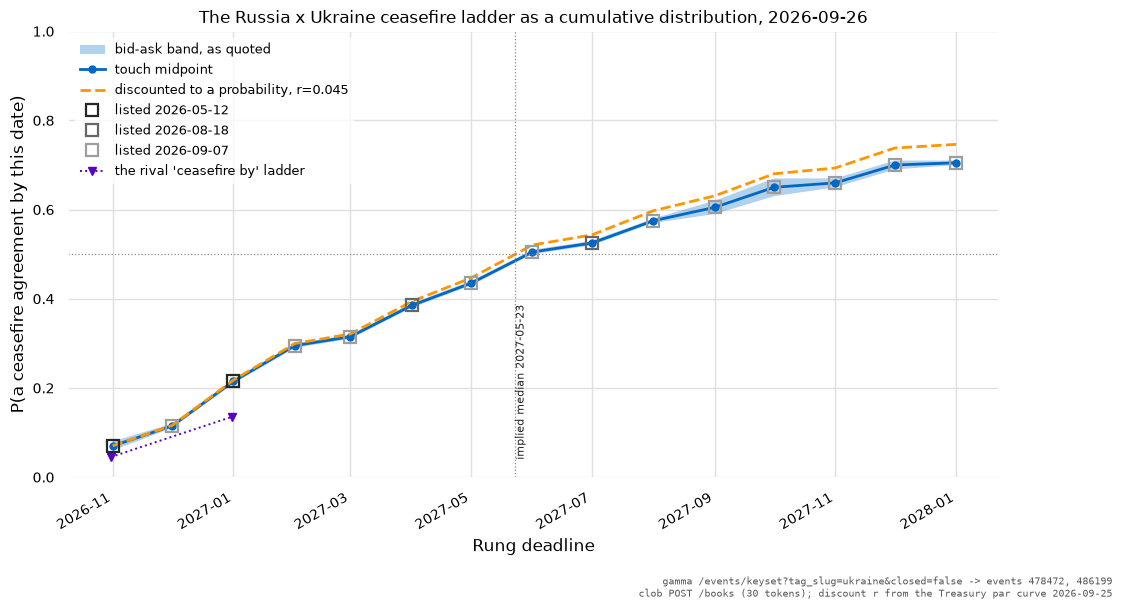

In [33]:
figure, axis = pyplot.subplots(figsize=(12, 6.5))
axis.set_axisbelow(True)

# The series go on as datetimes and matplotlib converts them; date2num is for
# the scalar axis arguments below, where the stubs want a float and the axis
# would otherwise be read as a plain number.
_dates = [datetime.combine(r.horizon, datetime.min.time()) for r in RUNGS]
_bids = numpy.array([r.bid for r in RUNGS], dtype=float)
_asks = numpy.array([r.ask for r in RUNGS], dtype=float)
_mids = (_bids + _asks) / 2
_corrected = numpy.array([row["cumulative"] for row in REPORT["interval_mass"]])

axis.fill_between(_dates, _bids, _asks, alpha=0.30, lw=0,
                  label="bid-ask band, as quoted")
axis.plot(_dates, _mids, lw=2.0, marker="o", markersize=5,
          label="touch midpoint")
axis.plot(_dates, _corrected, lw=2.0, ls="--",
          label=f"discounted to a probability, r={REPORT['rate']:.3f}")

# The listing generations: three batches of rungs, and the batch a rung belongs
# to explains more about its price than the calendar does.
_greys = ("0.15", "0.40", "0.62", "0.78")
_gen_colours = {gen: _greys[i % len(_greys)] for i, gen
                in enumerate(sorted({row["created"] for row in LADDER_ROWS}))}
for _row in LADDER_ROWS:
    axis.plot([datetime.combine(_row["horizon"], datetime.min.time())],
              [_row["mid"]], marker="s", markersize=9, mfc="none", mew=1.6,
              color=_gen_colours[_row["created"]], zorder=5)
for _created, _colour in _gen_colours.items():
    axis.plot([], [], marker="s", ls="none", markersize=9, mfc="none", mew=1.6,
              color=_colour, label=f"listed {_created}")

_rival_points = [(mx.parse_deadline(m["question"]),
                  (m["bestBid"] + m["bestAsk"]) / 2) for m in _rival_open]
axis.plot([datetime.combine(d, datetime.min.time()) for d, _ in _rival_points],
          [p for _, p in _rival_points], marker="v", ls=":", lw=1.4,
          label="the rival 'ceasefire by' ladder")

axis.axhline(0.5, color="0.55", lw=0.9, ls=":")
if REPORT["implied_median"]:
    axis.axvline(date2num(datetime.combine(REPORT["implied_median"], datetime.min.time())),
                 color="0.55", lw=0.9, ls=":")
    axis.text(date2num(datetime.combine(REPORT["implied_median"], datetime.min.time())),
              0.03, f" implied median {REPORT['implied_median']}", fontsize=8,
              rotation=90, va="bottom", alpha=0.85)

axis.set_ylim(0, 1)
axis.set_ylabel("P(a ceasefire agreement by this date)")
axis.set_xlabel("Rung deadline")
axis.set_title("The Russia x Ukraine ceasefire ladder as a cumulative distribution, "
               f"{ASOF}", fontsize=12)
axis.legend(loc="upper left", fontsize=9)
figure.autofmt_xdate()
stamp_source("gamma /events/keyset?tag_slug=ukraine&closed=false -> events 478472, 486199",
             "clob POST /books (30 tokens); discount r from the Treasury par curve 2026-09-25",
             figure=figure)

### 7.1 The interval masses, and the tick that swallows them

Differencing the corrected CDF gives the probability mass in each month, and
dividing by the survival probability gives the **hazard** — the chance of a
ceasefire in that month *given* there has not been one yet. That is the quantity
a reader actually wants, and it is the quantity the ladder cannot support.

Three bounds are printed beside each mass, all from observables.

**The tick.** Every open rung quotes on a one-cent tick, so each mass is a
difference of two one-cent-quantised numbers and carries a full tick of
quantisation error of its own. The last rung's month holds **0.8 of a tick** and
October 2027's holds 1.3 — both smaller than the error on the subtraction that
produced them.

**The spread.** An interval position is long the far rung and short the near
one, so the honest bounds on its mass are `bid_far − ask_near` at worst and
`ask_far − bid_near` at best. Where the lower bound is at or below zero the mass
is **not distinguishable from zero at the quoted prices**: October and December
2027 both bound negative. Several others are bounded but barely — September
2027's mass of 0.049 has bounds of 0.010 to 0.080, which is the spread doing all
of the work.

**The depth.** The executable size of an interval is the smaller of the far
rung's ask depth and the near rung's bid depth within a cent, in shares. The
largest interval position this ladder will fill within a cent of the touch is
**$463**, on the December 2026 month; the smallest is **$6**, on December 2027.
Every month after March 2027 fills under fifty dollars.

In [34]:
print(f"{'interval ending':20}{'days':>5}{'mass':>8}{'ticks':>7}{'haz':>8}{'haz/day':>9}"
      f"{'mass low':>10}{'mass high':>11}{'zero?':>7}{'shares':>9}{'$ cost':>9}")
INTERVALS: list[dict[str, Any]] = []
for _i, (_mass_row, _haz_row) in enumerate(zip(REPORT["interval_mass"], REPORT["hazard"])):
    _near = LADDER_ROWS[_i - 1] if _i else None
    _far = LADDER_ROWS[_i]
    # The first interval runs from today, so its mass is the price itself and its
    # bounds are just that rung's own bid and ask.
    _low = (_far["bid"] - _near["ask"]) if _near else _far["bid"]
    _high = (_far["ask"] - _near["bid"]) if _near else _far["ask"]
    _shares = min(_far["sh_ask"], _near["sh_bid"]) if _near else _far["sh_ask"]
    _cost = _shares * max(_high, 0.0)
    _row = {"label": _far["label"], "horizon": _far["horizon"],
            "mass": _mass_row["mass"], "days": _mass_row["interval_days"],
            "hazard": _haz_row["hazard"], "hazard_per_day": _haz_row["hazard_rate_per_day"],
            "low": _low, "high": _high, "shares": _shares, "cost": _cost}
    INTERVALS.append(_row)
    print(f"{_far['label'][:20]:20}{_mass_row['interval_days']:>5}"
          f"{_mass_row['mass']:>8.3f}{_mass_row['mass'] / 0.01:>7.1f}"
          f"{_haz_row['hazard']:>8.3f}{_haz_row['hazard_rate_per_day']:>9.4f}"
          f"{_low:>10.3f}{_high:>11.3f}"
          f"{('yes' if _low <= 0 else ''):>7}{_shares:>9,.0f}{_cost:>9,.0f}")

_zero = [r for r in INTERVALS if r["low"] <= 0]
_haz = numpy.array([r["hazard_per_day"] for r in INTERVALS])
print(f"\n{len(_zero)} of {len(INTERVALS)} interval masses are not distinguishable from "
      f"zero at the quoted prices")
print(f"masses of two ticks or less: "
      f"{sum(1 for r in INTERVALS if r['mass'] <= 0.02)} of {len(INTERVALS)}")
print(f"implied daily hazard ranges {_haz.min():.4f} to {_haz.max():.4f} "
      f"({_haz.max() / _haz.min():.1f}x), median {numpy.median(_haz):.4f}")
print(f"largest executable interval position within 1c: "
      f"${max(r['cost'] for r in INTERVALS):,.0f}; smallest "
      f"${min(r['cost'] for r in INTERVALS):,.0f}")

interval ending      days    mass  ticks     haz  haz/day  mass low  mass high  zero?   shares   $ cost
October 31             36   0.070    7.0   0.070   0.0020     0.060      0.080           5,598      448
November 30            30   0.046    4.6   0.049   0.0017     0.030      0.060           4,378      263
December 31            31   0.102   10.2   0.115   0.0039     0.090      0.110           4,206      463
January 31, 2027       31   0.082    8.2   0.105   0.0036     0.070      0.090           2,811      253
February 28, 2027      28   0.021    2.1   0.031   0.0011     0.010      0.030           2,733       82
March 31, 2027         31   0.073    7.3   0.107   0.0037     0.060      0.080             611       49
April 30, 2027         30   0.053    5.3   0.087   0.0030     0.040      0.060             274       16
May 31, 2027           31   0.074    7.4   0.134   0.0046     0.060      0.080             213       17
June 30, 2027          30   0.023    2.3   0.047   0.0016     0.

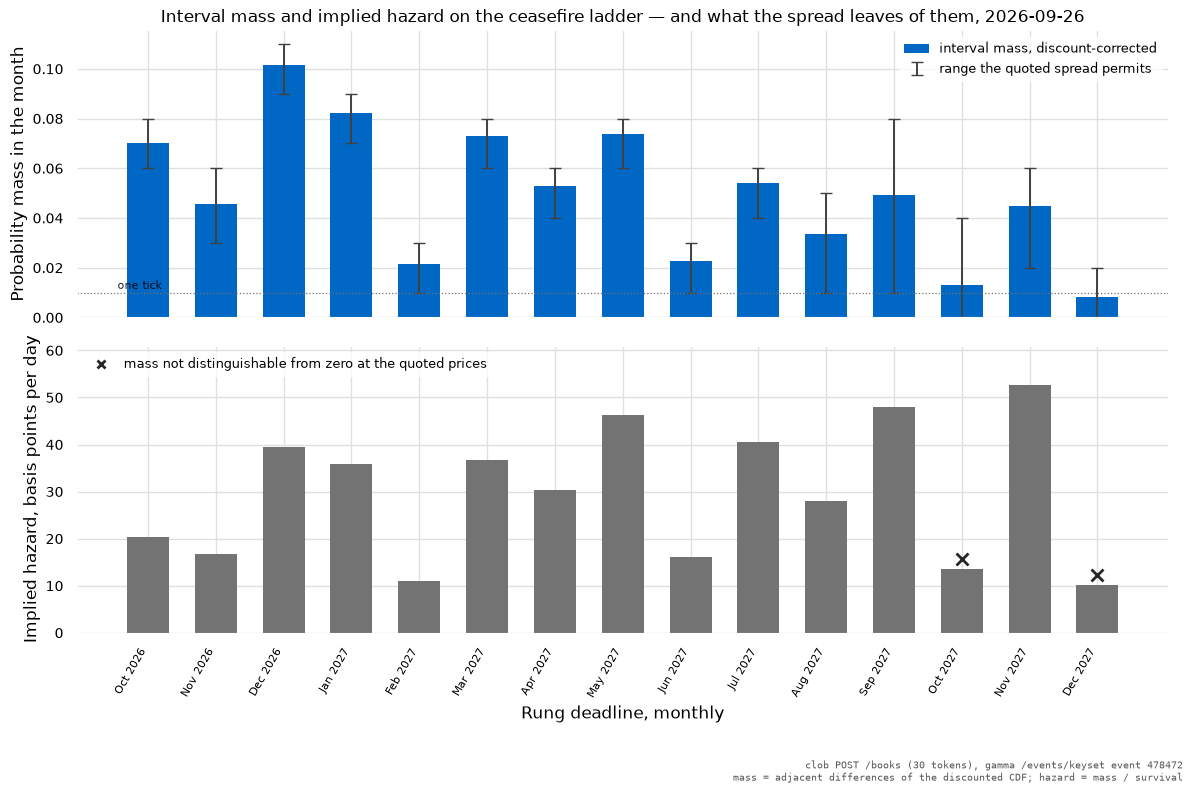

In [35]:
figure, (upper, lower) = pyplot.subplots(2, 1, figsize=(12, 8), sharex=True,
                                         height_ratios=[1.0, 1.0])
_x = numpy.arange(len(INTERVALS))
_mass = numpy.array([r["mass"] for r in INTERVALS])
_low = numpy.array([max(r["low"], 0.0) for r in INTERVALS])
_high = numpy.array([r["high"] for r in INTERVALS])

upper.bar(_x, _mass, width=0.62, label="interval mass, discount-corrected")
upper.errorbar(_x, (_low + _high) / 2, yerr=(_high - _low) / 2, fmt="none",
               ecolor="0.25", elinewidth=1.4, capsize=4,
               label="range the quoted spread permits")
upper.axhline(0.01, color="0.45", lw=0.9, ls=":")
upper.text(-0.45, 0.0115, "one tick", fontsize=8, ha="left", alpha=0.85)
upper.set_ylabel("Probability mass in the month")
upper.set_title("Interval mass and implied hazard on the ceasefire ladder — and what the "
                f"spread leaves of them, {ASOF}", fontsize=12)
upper.legend(loc="upper right", fontsize=9)

lower.bar(_x, [1e4 * r["hazard_per_day"] for r in INTERVALS], width=0.62, color="0.45")
lower.set_ylabel("Implied hazard, basis points per day")
lower.set_xticks(_x)
lower.set_xticklabels([rung_label(r["horizon"]) for r in INTERVALS], rotation=60,
                      ha="right", fontsize=8)
lower.set_xlabel("Rung deadline, monthly")
_ceiling = 1e4 * max(r["hazard_per_day"] for r in INTERVALS)
for _i, _row in enumerate(INTERVALS):
    if _row["low"] <= 0:
        lower.plot([_i], [1e4 * _row["hazard_per_day"] + 0.04 * _ceiling],
                   marker="x", markersize=9, mew=2.0, color="0.15")
lower.set_ylim(0, 1.16 * _ceiling)
lower.plot([], [], marker="x", ls="none", mew=2.0, color="0.15",
           label="mass not distinguishable from zero at the quoted prices")
lower.legend(loc="upper left", fontsize=9)
figure.tight_layout()
stamp_source("clob POST /books (30 tokens), gamma /events/keyset event 478472",
             "mass = adjacent differences of the discounted CDF; hazard = mass / survival",
             figure=figure)

### 7.2 Quoted rather than traded, and the fingerprint of it

The hazard in that lower panel swings between ten and fifty-three basis points a
day, a factor of five, month to month, with nothing in the war corresponding to
any of the swings. The structural tests said the ladder was coherent; the hazard
says the coherence is not informative. Three measurements explain the
difference and none of them is about Ukraine.

**Lifetime volume on the thinnest rungs is four figures.** The four least-traded
contracts on the ladder have turned over **$818, $1,043, $1,643 and $1,866** in
their whole lives — August, September, July and April 2027 — against $2.7
million on the December 2026 rung. The research pass measured $818, $976, $1,643
and $3,018 on its own four 2027 rungs a few hours earlier; three of those four
are the same contracts, and the $976 has become $1,043, which is the entire
day's trade in that month of the war.

**Depth is near-uniform where volume is not.** Lifetime volume across the
fifteen rungs spans a factor of **3,282**; depth within a cent spans a factor of
**14.7**, and the rank correlation between the two is **0.18** — effectively
none. A ladder where what is quoted bears no relation to what has traded, at
the same size on every rung, is one participant quoting a curve between the
front rung and one dollar. It is not forty-four traders independently pricing
November 2027. The generation table below says the same thing a second way: as
the median lifetime volume falls from $2.2M to $162k to $5.3k across the three
listing batches, the median depth within a cent barely moves — $753, $735, $535.

**And the rungs arrive in batches.** The listing dates split the ladder into
three generations: two rungs from the event's creation in May, two added in
August, and **eleven added on a single day in September**, filling in every
month between the ones that already existed. Eleven monthly prices created at
once, on a curve anchored at both ends, is a description of how the numbers were
produced rather than of what they are about.

`metrics.NOT_COMPUTABLE` names this limit honestly under
`market_maker_identity`: whether a smooth ladder is many traders or one maker
**cannot be settled from public data**. The hazard shape, the flat depth and the
listing batches are a hint, not an answer. What can be said without hedging is
the negative: at these depths the ladder's monthly structure is not a
measurement of anything, while its *front* rungs — October and December 2026,
at $1.7M and $2.7M of lifetime volume and $285k and $269k of open interest —
are.

In [36]:
print(f"{'rung':20}{'listed':11}{'days out':>9}{'mid':>7}{'volume':>11}{'OI':>9}"
      f"{'turnover':>10}{'dep1c bid':>11}{'dep1c ask':>11}")
for _row in LADDER_ROWS:
    print(f"{_row['label'][:20]:20}{_row['created']:11}"
          f"{(_row['horizon'] - ASOF).days:>9}{_row['mid']:>7.3f}"
          f"{_row['volume']:>11,.0f}{_row['oi']:>9,.0f}"
          f"{_row['volume'] / _row['oi']:>10.1f}x"
          f"{_row['dep_bid']:>11,.0f}{_row['dep_ask']:>11,.0f}")

print(f"\nby listing generation:")
print(f"  {'listed':12}{'rungs':>7}{'median volume':>15}{'median dep1c bid':>18}"
      f"{'median mass':>13}")
for _created in sorted({r["created"] for r in LADDER_ROWS}):
    _batch = [r for r in LADDER_ROWS if r["created"] == _created]
    _labels = {r["label"] for r in _batch}
    _mass = [i["mass"] for i in INTERVALS if i["label"] in _labels]
    print(f"  {_created:12}{len(_batch):>7}"
          f"{numpy.median([r['volume'] for r in _batch]):>15,.0f}"
          f"{numpy.median([r['dep_bid'] for r in _batch]):>18,.0f}"
          f"{numpy.median(_mass):>13.3f}")

def rank(values: list[float]) -> NDArray[numpy.float64]:
    """Ranks, for a correlation over fifteen points that is a shape test not a test."""
    return numpy.argsort(numpy.argsort(numpy.asarray(values, dtype=float))).astype(float)


_volumes = [r["volume"] for r in LADDER_ROWS]
_depths = [r["dep_bid"] for r in LADDER_ROWS]
print(f"\nlifetime volume spans {max(_volumes) / min(_volumes):,.0f}x across the ladder; "
      f"depth within 1c spans {max(_depths) / min(_depths):.1f}x")
print(f"rank correlation between depth within 1c and lifetime volume: "
      f"{float(numpy.corrcoef(rank(_depths), rank(_volumes))[0, 1]):.2f}")
print(f"\nthe four least-traded rungs:")
for _row in sorted(LADDER_ROWS, key=lambda r: r["volume"])[:4]:
    print(f"  {_row['label'][:20]:20} lifetime volume ${_row['volume']:>9,.0f}   "
          f"depth within 1c ${_row['dep_bid']:>6,.0f} bid / ${_row['dep_ask']:>6,.0f} ask")
print(f"the two front rungs: volume "
      f"${LADDER_ROWS[0]['volume']:,.0f} and ${LADDER_ROWS[2]['volume']:,.0f}, "
      f"open interest ${LADDER_ROWS[0]['oi']:,.0f} and ${LADDER_ROWS[2]['oi']:,.0f}")

rung                listed      days out    mid     volume       OI  turnover  dep1c bid  dep1c ask
October 31          2026-05-12        36  0.070  1,738,779  284,887       6.1x        615        480
November 30         2026-09-07        66  0.115     16,127   11,239       1.4x        554        532
December 31         2026-05-12        97  0.215  2,685,293  269,009      10.0x        891        965
January 31, 2027    2026-09-07       128  0.295     38,187   20,312       1.9x        767        853
February 28, 2027   2026-09-07       156  0.315      7,114    4,359       1.6x        186      1,426
March 31, 2027      2026-08-18       187  0.385    166,212   23,623       7.0x        335        467
April 30, 2027      2026-09-07       217  0.435      1,866      980       1.9x         90        123
May 31, 2027        2026-09-07       248  0.505      5,301    4,091       1.3x        535        341
June 30, 2027       2026-08-18       278  0.525    157,524   30,402       5.2x      1,134   

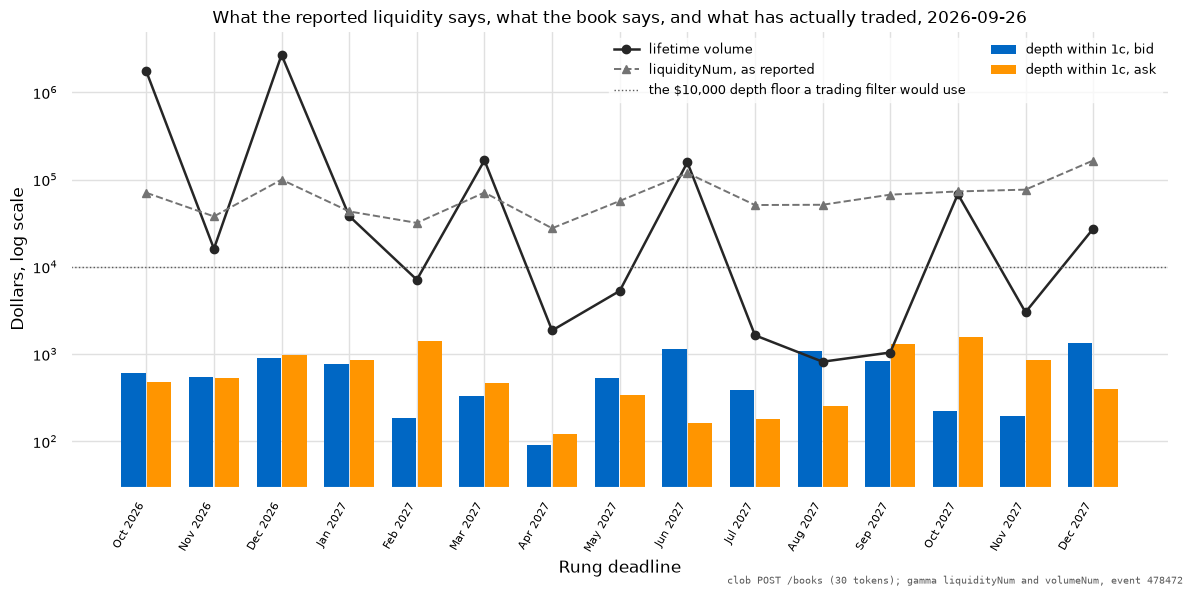

In [37]:
figure, axis = pyplot.subplots(figsize=(12, 6.0))
axis.set_axisbelow(True)
_x = numpy.arange(len(LADDER_ROWS))
axis.bar(_x - 0.19, [r["dep_bid"] for r in LADDER_ROWS], width=0.36,
         label="depth within 1c, bid")
axis.bar(_x + 0.19, [r["dep_ask"] for r in LADDER_ROWS], width=0.36,
         label="depth within 1c, ask")
axis.plot(_x, [r["volume"] for r in LADDER_ROWS], marker="o", lw=1.8, color="0.15",
          label="lifetime volume")
axis.plot(_x, [r["liq"] for r in LADDER_ROWS], marker="^", lw=1.4, ls="--", color="0.45",
          label="liquidityNum, as reported")
axis.axhline(10_000, color="0.35", lw=1.0, ls=":",
             label="the $10,000 depth floor a trading filter would use")
axis.set_yscale("log")
axis.set_ylim(30, 5e6)
axis.set_ylabel("Dollars, log scale")
axis.set_xticks(_x)
axis.set_xticklabels([rung_label(r["horizon"]) for r in LADDER_ROWS], rotation=60,
                     ha="right", fontsize=8)
axis.set_xlabel("Rung deadline")
axis.set_title("What the reported liquidity says, what the book says, and what has "
               f"actually traded, {ASOF}", fontsize=12)
axis.legend(loc="upper right", fontsize=9, ncols=2)
figure.tight_layout()
stamp_source("clob POST /books (30 tokens); gamma liquidityNum and volumeNum, event 478472",
             figure=figure)

## 8. Discovery — how you find markets worth watching

Three queries do the whole job, and none of them is a search.

```text
enumerate       GET /events/keyset?tag_slug=<tag>&closed=false&order=volume
                    &ascending=false&limit=100   + after_cursor
detect new      GET /events/keyset?tag_slug=<tag>&order=createdAt&ascending=false
                    &start_date_min=<last run>
detect resolved GET /events/keyset?closed=true&tag_slug=<tag>&order=closedTime
                    &ascending=false   then GET /v2/resolutions?condition=<20 ids>
```

Four traps sit in that pattern.

**`limit` caps silently at 100** — ask for a thousand, get a hundred, with no
warning. **`offset` hard-stops** at 20,000 with a 422 telling you to use keyset,
which is a failure that arrives mid-backfill. **Unhonoured parameters do not
error**: `end_date_min` on `/markets/keyset` changed one response byte-for-byte
not at all, so every filter has to be confirmed by inspecting results rather
than by reading the docs. And **`updatedAt` is not a change signal** — the five
newest geopolitics events share one identical value to the microsecond, because
it is batch-stamped. Order on `createdAt`.

**A curated tag registry is mandatory, not a convenience.** There are at least
four thousand distinct tag slugs and they are dirty: `multi-strikes` means
multiple *strike prices*, and trusting it drags about a thousand Bitcoin
threshold markets into a conflict count — 1,385 markets before the correction
against 365 after. `utils/polymarket.py` therefore defines the universe by hand,
seeded from named concepts and extended one hop through each seed's
`related-tags`, keeping only the political and macro neighbours. That is the same
shape as the hand-maintained dataset registry the CDC tools already use, and it
needs the same thing: tests, or the category counts lie.

The one live read here is the hop itself, on `geopolitics`, which returns a
ready-made theatre watchlist — and every one of its seventeen neighbours is in
the registry, which is the check that the hop was worth making. The same call on
`elections` returns nothing at all, so an election corpus needs its country axis
built by hand.

In [38]:
print(f"the registry in utils/polymarket.py: {len(pm.POLITICAL_TAGS)} political + "
      f"{len(pm.FINANCIAL_TAGS)} financial/macro = {len(pm.ALL_TAGS)} tags")
print(f"  political  {', '.join(pm.POLITICAL_TAGS[:12])} ...")
print(f"  financial  {', '.join(pm.FINANCIAL_TAGS[:12])} ...")

_related = read("/tags/slug/geopolitics/related-tags/tags",
                lambda: READER.related_tags("geopolitics"))
print(f"\ngeopolitics related-tags -> {len(_related)} neighbours:")
print(f"  {', '.join(sorted(t['slug'] for t in _related))}")
_in_registry = {t["slug"] for t in _related} & set(pm.ALL_TAGS)
print(f"  {len(_in_registry)} of the {len(_related)} are in the registry; "
      f"{len({t['slug'] for t in _related}) - len(_in_registry)} are not")

# The census the harvest ran on, from the manifest rather than re-read: the sum
# double-counts, because an event carries several tags at once.
_census = _manifest["census_closed_events_by_tag"]
print(f"\nthe ten largest tags in the closed corpus, by event count:")
for _slug, _count in sorted(_census.items(), key=lambda kv: -kv[1])[:10]:
    print(f"  {_slug:26}{_count:>8,}")
print(f"  {'sum with overlap':26}{_manifest['census_sum_with_overlap']:>8,} across "
      f"{len(_census)} tags, deduplicated to {_manifest['events']:,} events")

the registry in utils/polymarket.py: 42 political + 16 financial/macro = 58 tags
  political  politics, elections, geopolitics, world, trump, midterms, senate-midterms, house-elections, governor-midterms, mayoral-elections, global-elections, primaries ...
  financial  economy, fed, inflation, fed-rates, macro-indicators, gdp, global-rates, taxes, treasuries, consumer, housing, labor ...

geopolitics related-tags -> 17 neighbours:
  china, cuba, gaza, india-pakistan, iran, israel, lebanon, middle-east, oil, sudan, syria, thailand-cambodia, turkey, ukraine, ukraine-map, venezuela, yemen
  17 of the 17 are in the registry; 0 are not

the ten largest tags in the closed corpus, by event count:
  politics                     7,795
  trump                        2,934
  geopolitics                  2,112
  world                        1,729
  elections                    1,389
  economy                      1,095
  global-elections               929
  middle-east                    888
  us-p

## 9. Longshot bias and calibration, measured on this venue's own corpus

Everything above is about whether a price can be traded. This is about whether it
was right, and it is the only section that can be answered without a single live
call: the corpus on disk holds **72,838 closed markets**, of which 46,223 have
both a daily price path of at least three prints and a settled outcome from
`/v2/resolutions`. The label never comes from the last price — **26.9% of paths
disagree with the settled value**, because the resolving move usually lands
inside one twelve-hour bucket and the daily print misses it.

One reduction makes the sample sizes honest. Consecutive days of one market are
approximately the same forecast, so counting market-days overstates the
information by roughly the length of the market. `corpus.market_bucket_rows`
keeps **one observation per market per horizon bucket**, the one nearest the
bucket's geometric centre, which is a less arbitrary choice than first (biased
long) or last (biased to the resolving move).

The published figure this is supposed to reproduce is a loss of **19.3 cents per
dollar staked below ten cents**. It reproduces, and then it falls apart when you
look at where it comes from.

In [39]:
PANEL = corpus.load_panel(venues=("polymarket",))
ROWS = corpus.market_bucket_rows(PANEL)
GEO = PANEL.market_array("geo")[ROWS["m_index"]]
print(json.dumps(PANEL.describe(), indent=1, default=str))
print(f"\nmarket-bucket rows {ROWS['price'].size:,}, of which geopolitics "
      f"{int(GEO.sum()):,}")
print(f"terminal print agrees with the settled outcome on "
      f"{_manifest['price_paths']['terminal_print_agrees_with_settled_outcome']:,} paths "
      f"and disagrees on {_manifest['price_paths']['terminal_print_disagrees']:,} "
      f"({100 * _manifest['price_paths']['terminal_print_disagrees'] / (_manifest['price_paths']['terminal_print_agrees_with_settled_outcome'] + _manifest['price_paths']['terminal_print_disagrees']):.1f}%)")

print(f"\nfavourite-longshot bias, every closed Polymarket market on disk")
print(f"{'band':>7}{'rows':>9}{'mean price':>12}{'realised':>10}{'gap':>9}{'per $':>9}")
for _label, _mask in (("all", numpy.ones(ROWS["price"].size, dtype=bool)),
                      ("geopolitics", GEO)):
    print(f"  -- {_label} --")
    for _row in corpus.longshot_table(ROWS["price"][_mask], ROWS["outcome"][_mask]):
        print(f"{_row['band']:>7}{_row['n']:>9,}{_row['mean_price']:>12.4f}"
              f"{_row['realised']:>10.4f}{_row['gap_cents']:>+8.2f}c"
              f"{_row['per_dollar']:>+8.1f}%")

{
 "markets": 46223,
 "observations": 1646552,
 "by_venue": {
  "polymarket": 46223
 },
 "obs_by_venue": {
  "polymarket": 1646552
 },
 "max_horizon_days": 674.99853515625
}

market-bucket rows 145,898, of which geopolitics 19,453
terminal print agrees with the settled outcome on 40,333 paths and disagrees on 14,825 (26.9%)

favourite-longshot bias, every closed Polymarket market on disk
   band     rows  mean price  realised      gap    per $
  -- all --
    <2c   60,624      0.0044    0.0021   +0.23c   -51.9%
   2-5c   12,603      0.0326    0.0213   +1.13c   -34.6%
  5-10c   10,194      0.0704    0.0566   +1.38c   -19.6%
 10-25c   15,391      0.1653    0.1390   +2.63c   -15.9%
 25-50c   19,733      0.3805    0.2884   +9.21c   -24.2%
 50-75c   12,109      0.5945    0.5775   +1.70c    -2.9%
 75-90c    5,142      0.8261    0.8565   -3.04c    +3.7%
   >90c   10,102      0.9725    0.9846   -1.21c    +1.2%
  -- geopolitics --
    <2c    7,687      0.0055    0.0017   +0.38c   -69.2%
   2-5c

**The published number reproduces exactly where the published band is, and
nowhere else.** In the 5–10 cent band a dollar staked returns **−19.6%**, against
the −19.3 cents the literature quotes. Widen the band downward and it gets far
worse — −34.6% at 2–5 cents, **−51.9% below 2 cents** — because the sub-2-cent
population is not a population of forecasts at all. It is the dead legs of
neg-risk events, the Oprah Winfrey rows of section 6, priced at five hundredths
of a cent. Pooling them into "below 10 cents" produces a number that is mostly
about them.

**And the absolute gap tells a different story from the ratio.** Below two cents
the mean price exceeds the realised rate by **0.23 of a cent**. That is the
correction a reader would actually apply, and it is negligible; the −51.9% is the
same fact divided by a very small number. The two columns are printed together
for exactly this reason, and the absolute gap is the robust one.

**Longshot bias is a property of the population, not of the venue.** Restricted
to the geopolitics tag the pattern is gone below ten cents — a gap of +0.01 of a
cent in the 5–10 band — and *inverts* in the 10–25 cent band, where the realised
rate exceeds the price by 3.3 cents. Geopolitical longshots on this venue have
been underpriced, not overpriced. This is consistent with the published result
being grouping-dependent: equal-weighted, longshots lose 6.3 cents per dollar;
grouped by parent event, they gain 4.1. So the section-4 haircut is a *default*
to be checked per population and not a constant.

One band is worth flagging because it is not longshot bias at all: 25–50 cents
carries a **+9.2 cent** gap over the whole corpus and −1.1 in geopolitics. The
difference is the non-geopolitical political book — shutdown, nomination and
mention markets — and a corpus-wide correction curve would be fitting that.

In [40]:
print(f"{'horizon':>10}{'rows':>8}{'markets':>9}{'base':>8}{'mean p':>8}{'brier':>8}"
      f"{'skill':>8}{'slope lin':>10}{'slope logit':>12}")
HORIZON_STATS: list[dict[str, Any]] = []
for _label, _mask in (("all", numpy.ones(ROWS["price"].size, dtype=bool)),
                      ("geopolitics", GEO)):
    print(f"  -- {_label} --")
    for _i, _name in enumerate(corpus.HORIZON_LABELS):
        _sel = (ROWS["bucket"] == _i) & _mask
        if _sel.sum() < 30:
            print(f"{_name:>10}{int(_sel.sum()):>8}   too few to report")
            continue
        _stats = corpus.brier(ROWS["price"][_sel], ROWS["outcome"][_sel])
        _stats.update(corpus.calibration_slope(ROWS["price"][_sel], ROWS["outcome"][_sel]))
        _stats.update({"horizon": _name, "subset": _label,
                       "n_markets": int(numpy.unique(ROWS["m_index"][_sel]).size),
                       "mean_price": float(ROWS["price"][_sel].mean())})
        HORIZON_STATS.append(_stats)
        print(f"{_name:>10}{_stats['n']:>8,}{_stats['n_markets']:>9,}"
              f"{_stats['base_rate']:>8.3f}{_stats['mean_price']:>8.3f}"
              f"{_stats['brier']:>8.4f}{_stats['skill']:>+8.3f}"
              f"{_stats['slope_linear']:>10.3f}{_stats['slope_logit']:>12.3f}")

# The interval on the longest geopolitics bucket that has any markets at all,
# resampling markets rather than rows because rows from one market are not
# independent.
_sel = (ROWS["bucket"] == 5) & GEO           # 180-365 days
_ci = corpus.bootstrap_ci(ROWS["price"][_sel], ROWS["outcome"][_sel], ROWS["m_index"][_sel],
                          lambda p, o: corpus.calibration_slope(p, o)["slope_logit"],
                          draws=400)
print(f"\ngeopolitics at 180-365 days: {int(numpy.unique(ROWS['m_index'][_sel]).size)} markets, "
      f"logit slope {corpus.calibration_slope(ROWS['price'][_sel], ROWS['outcome'][_sel])['slope_logit']:.3f} "
      f"with a 95% market-resampled interval of ({_ci[0]:.2f}, {_ci[1]:.2f})")
print(f"markets in the corpus with a horizon beyond one year: "
      f"{int((ROWS['bucket'] >= 6).sum())}; beyond two years: "
      f"{int((ROWS['bucket'] >= 7).sum())}; the longest path is "
      f"{PANEL.horizon.max() / 365.25:.2f} years")

   horizon    rows  markets    base  mean p   brier   skill slope lin slope logit
  -- all --
       <1d  44,491   44,491   0.226   0.221  0.0425  +0.757     1.034       1.340
      1-7d  46,069   46,069   0.224   0.223  0.0765  +0.560     1.026       1.133
     7-30d  33,352   33,352   0.186   0.220  0.0910  +0.399     0.932       1.034
    30-90d  14,738   14,738   0.167   0.237  0.0987  +0.291     0.839       1.103
   90-180d   4,935    4,935   0.156   0.223  0.0876  +0.335     0.888       1.066
  180-365d   2,231    2,231   0.154   0.277  0.1103  +0.154     0.794       0.983
      1-2y      82       82   0.085   0.232  0.0977  -0.252     0.527      -0.250
       >2y       0   too few to report
  -- geopolitics --
       <1d   5,712    5,712   0.269   0.232  0.0362  +0.816     1.067       1.360
      1-7d   6,098    6,098   0.267   0.226  0.0814  +0.584     1.081       1.146
     7-30d   4,681    4,681   0.229   0.225  0.1144  +0.351     1.000       1.248
    30-90d   2,268    2,268

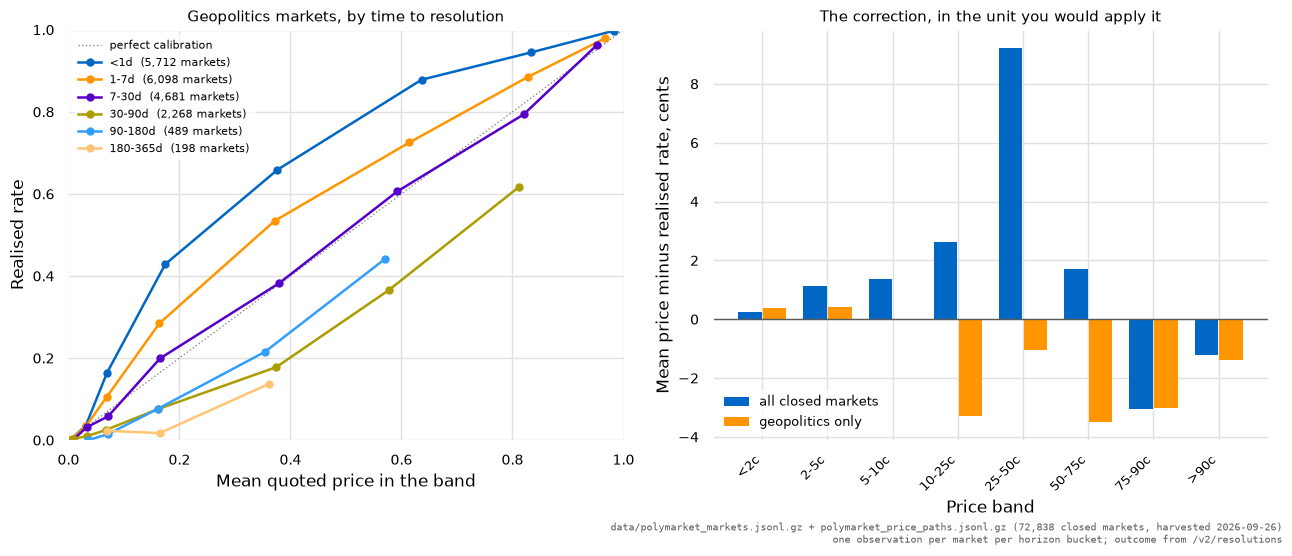

In [41]:
figure, (left, right) = pyplot.subplots(1, 2, figsize=(13, 5.6))
left.set_axisbelow(True)
left.plot([0, 1], [0, 1], color="0.55", lw=1.0, ls=":", label="perfect calibration")
for _i, _name in enumerate(corpus.HORIZON_LABELS):
    _sel = (ROWS["bucket"] == _i) & GEO
    if _sel.sum() < 150:
        continue
    _curve = corpus.reliability(ROWS["price"][_sel], ROWS["outcome"][_sel])
    _keep = [row for row in _curve if row["n"] >= 40]
    left.plot([row["mean_price"] for row in _keep], [row["realised"] for row in _keep],
              marker="o", markersize=5, lw=1.8,
              label=f"{_name}  ({int(numpy.unique(ROWS['m_index'][_sel]).size):,} markets)")
left.set_xlim(0, 1)
left.set_ylim(0, 1)
left.set_xlabel("Mean quoted price in the band")
left.set_ylabel("Realised rate")
left.set_title("Geopolitics markets, by time to resolution", fontsize=11)
left.legend(loc="upper left", fontsize=8)

right.set_axisbelow(True)
_bands = [row["band"] for row in corpus.longshot_table(ROWS["price"], ROWS["outcome"])]
_x = numpy.arange(len(_bands))
for _offset, (_label, _mask) in zip((-0.19, 0.19),
                                    (("all closed markets",
                                      numpy.ones(ROWS["price"].size, dtype=bool)),
                                     ("geopolitics only", GEO))):
    _table = corpus.longshot_table(ROWS["price"][_mask], ROWS["outcome"][_mask])
    right.bar(_x + _offset, [row["gap_cents"] for row in _table], width=0.36, label=_label)
right.axhline(0.0, color="0.35", lw=1.0)
right.set_xticks(_x)
right.set_xticklabels(_bands, rotation=45, ha="right", fontsize=9)
right.set_xlabel("Price band")
right.set_ylabel("Mean price minus realised rate, cents")
right.set_title("The correction, in the unit you would apply it", fontsize=11)
right.legend(loc="lower left", fontsize=9)
figure.tight_layout()
stamp_source("data/polymarket_markets.jsonl.gz + polymarket_price_paths.jsonl.gz "
             f"({_manifest['markets']:,} closed markets, harvested {_manifest['harvested_at'][:10]})",
             "one observation per market per horizon bucket; outcome from /v2/resolutions",
             figure=figure)

**Calibration decays with horizon, and it runs out before the question this
venue is interesting for.** Brier skill against a constant climatological
forecast falls from +0.76 inside a day to +0.15 at six to twelve months, and the
logit slope stays above one at short range — the compression toward fifty per
cent that the literature reports as a structural property of political prediction
markets on both this venue and Kalshi, not an artefact of one platform.

Restricted to geopolitics at six to twelve months the sample is **198 markets**
and the logit slope is 0.56 with a market-resampled interval of **(0.10, 1.53)**.
That interval contains 1.0 and most of the plausible alternatives; it does not
distinguish a calibrated venue from an uncalibrated one. Beyond a year the corpus
holds **82 market-observations in total and none past two years**, because
Polymarket's long-dated markets have not resolved yet. The longest path on disk is
1.85 years.

So the honest statement about the ladder in section 7 is not that its far rungs
are miscalibrated. It is that **no evidence about them exists** — not here, and
not in any published source, none of which reports calibration beyond one month
from any venue. The corpus is what will eventually answer it, and it can only
answer it by waiting.

## 10. The quality catalogue, and what it cannot see

`utils/metrics.py` is written to be complete rather than convenient: every
measure of market quality that public, unauthenticated data supports, each with a
*measures* line, a *blind to* line, and a good/bad range calibrated against live
measurement rather than invented. Its silences are deliberate —
`NOT_COMPUTABLE` names nine things a trader would want and states why no amount
of public data will produce them.

The awkward result is in the discrimination table. Split the closed corpus into
quintiles of each quality field at a fixed horizon, standardise each bin to the
whole sample's price mix so that "cheap" is not mistaken for "bad", and ask
whether the field orders calibration. Three families come out.

**The vendor's live quality fields cannot be tested at all.** `liquidityNum`,
`spread` and `competitive` collapse to a single quantile bin, because a closed
market's book is gone and the fields are zero or absent on every settled row.
Nothing in the archive can say whether `liquidityNum` predicted anything, and
nothing ever will: the fields are not versioned upstream, so the only way to
find out is to start snapshotting them daily from now on. That is the same
irrecoverable-by-construction problem as `criteria_drift` — `description` is
editable and nothing keeps the old text, so what a market promised while it
traded at 0.40 is gone once it is edited.

**Two fields leak the answer and must be discarded.** `best_bid` appears to be
the strongest discriminator in the table, moving standardised absolute bias from
9 cents to **76 cents** across its quintiles with a rank correlation of 1.00.
That is not a quality signal: on a settled market `bestBid` is frozen at the
resolving value, so the field *is* the outcome. Standardising the price mix does
not protect against a column that contains the label, which is worth stating
plainly because it is the most common way a backtest of this kind goes wrong.

**The path measures work, and `volume` works despite being uninterpretable.**
Median absolute daily move, distinct price levels, the number of prints and the
fraction of unchanged days all order calibration in the expected direction —
markets that move, and that are quoted at many levels, are better calibrated.
`volume_num` is the strongest honest column, taking standardised absolute bias
from 10.6 cents in the lowest quintile to 1.6 in the highest. Section 6 said
never to use volume as a quality filter and that stands for its *level*, which
nobody can apportion; it evidently still works as an *ordering*. A filter can
work while the number it filters on means nothing, and the two claims should not
be collapsed.

In [42]:
_catalogue = json.loads((corpus.DATA / "metric_catalogue.json").read_text())
print(f"the catalogue covers {len(_catalogue['coverage'])} measures across four venues; "
      f"on Polymarket:")
_status: dict[str, list[str]] = {}
for _metric, _venues in _catalogue["coverage"].items():
    _status.setdefault(_venues["polymarket"]["status"], []).append(_metric)
for _key in sorted(_status):
    print(f"  {_key:8} {len(_status[_key]):>3}  {', '.join(_status[_key][:4])}"
          f"{' ...' if len(_status[_key]) > 4 else ''}")

print(f"\nNOT_COMPUTABLE from public data -- {len(mx.NOT_COMPUTABLE)} entries:")
for _name, _why in mx.NOT_COMPUTABLE.items():
    print(f"  {_name}")
    print(f"      {_why.split('. ')[0]}.")

_mask = (ROWS["bucket"] >= 2) & (ROWS["bucket"] <= 3)          # 7 to 90 days
_columns = corpus.polymarket_quality(PANEL)
_discrimination = corpus.metric_discrimination(PANEL, ROWS, _columns, mask=_mask, n_bins=5)
print(f"\ndoes a quality field order calibration? 7-90 day horizon, "
      f"{int(_mask.sum()):,} rows, quintiles, standardised to the sample's price mix")
print(f"{'field':22}{'markets':>9}{'lowest bin':>12}{'highest bin':>13}"
      f"{'|bias| lo':>11}{'|bias| hi':>11}{'change':>9}{'rho':>7}")
for _entry in sorted(_discrimination, key=lambda e: -abs(e.get("d_abs_bias_std") or 0.0)):
    if not _entry["usable"]:
        print(f"{_entry['metric']:22}{'-':>9}   not testable: {_entry['reason']}")
        continue
    print(f"{_entry['metric']:22}{_entry['n_markets']:>9,}"
          f"{_entry['bins'][0]['median_value']:>12.4g}{_entry['bins'][-1]['median_value']:>13.4g}"
          f"{100 * _entry['abs_bias_std_lo']:>10.2f}c{100 * _entry['abs_bias_std_hi']:>10.2f}c"
          f"{100 * _entry['d_abs_bias_std']:>+8.2f}c{_entry['rho_abs_bias_std']:>7.2f}")

the catalogue covers 17 measures across four venues; on Polymarket:
  no         1  quote_age
  partial    1  time_to_resolution / market_age
  yes       15  depth_within_1c / depth_within_5c, absolute_spread / relative_spread, midpoint_vs_last_trade_divergence, open_interest ...

NOT_COMPUTABLE from public data -- 9 entries:
  quote_age
      No venue timestamps an order-book level.
  order_flow_toxicity
      Requires signed trade direction (buyer- or seller-initiated).
  true_unique_traders
      Polymarket /holders counts wallets, and one person may hold many: the 2024 'French whale' traded >$85m through four accounts that Polymarket itself later confirmed were one trader.
  wash_trade_share
      volumeClob equals volumeNum exactly at every percentile across 3,005 political markets, so there is no cross-check inside the API.
  market_maker_identity
      Whether a smooth ladder is 44 independent traders or one maker interpolating cannot be settled from public data.
  resolution_so

## 11. Resolution — who decides, on what text, and what happens when it is disputed

The contract is the prose. There is no structured field that carries it:
`resolutionSource` carries nothing usable and `resolvedBy` is an Ethereum
address — the UMA adapter — rather than a source. So the definition of every
market on this venue exists only as free text in `description`, which has to be
parsed and cannot be queried.

It is better prose than it is usually given credit for. The ceasefire rung's text
enumerates what qualifies — "a broader peace deal, normalization agreement,
political framework, truce, or humanitarian pause will qualify if it includes a
mutually agreed suspension of direct military engagement, to be effective on a
specified date" — and what does not, excluding "informal understanding,
backchannel communication, de-escalation without an announced agreement, or
unilateral pause", and excluding partial agreements that "only apply to specific
conflict categories". The NATO–Russia market goes further and names historical
precedents as calibration.

But the standard is **"a consensus of credible sources"**, and the text provides
that where government statements conflict with credible field reporting, the
reporting takes precedence. Precise criteria, discretionary judge. The mechanism
is UMA's optimistic oracle: anyone proposes an answer with a bond, there is a
two-hour challenge window, and a challenge escalates to a token-holder vote. The
bond on every rung here is **$500**, which is not a number that scales with the
stake — it is $500 on a market with $269,000 of open interest.

Three settlements are worth knowing about, all *reported* by press rather than
verified here, and all in this project's own categories: the **Ukraine mineral
deal** resolved Yes in March 2025 with no agreement reached, on a vote where one
holder cast 5M tokens across three accounts; **Zelenskyy's suit** resolved No on a
$237M market after two dispute rounds, despite forty-plus outlets describing the
garment as a suit; and the **US–Iran permanent peace deal** resolved Yes on a
memorandum that itself provided for a further sixty days of negotiation.

Two structural facts follow from that, and both are in the data below.
**Settlement is not boolean** — a UMA "Unknown" vote settles each token at $0.50,
and thirty markets in this corpus did. And **`price` is 1e18-scaled** with the
string `"69"` as the unresolved sentinel, so a loader that casts it naively gets
a probability of a billion billion.

The last table is the one that matters most for reading a ladder. Sixty-three of
1,034 cumulative ladders in the corpus settled **non-monotonically** — YES at one
deadline and NO at a later one — which is arithmetically impossible for a CDF. It
is not a venue failure. It is a recurrence failure: "X by T" is a CDF only when X
can happen at most once, and for a recurring event the re-issues are *rolling*
windows rather than nested ones. The North Korea missile-test row below settles
YES, NO, YES down the deadline axis for exactly that reason, and differencing it
would be meaningless.

In [43]:
_resolutions = read("/v2/resolutions?event_id=478472",
                    lambda: READER.resolutions(event_ids=[LADDER["id"]]))
_by_status: dict[str, int] = {}
for _row in _resolutions:
    _by_status[_row["status"]] = _by_status.get(_row["status"], 0) + 1
print(f"the ladder's 18 markets at /v2/resolutions: {_by_status}")
_settled = next(r for r in _resolutions if r["status"] == "resolved")
print(f"\none settled record, decoded by polymarket.resolution_outcome:")
for _key, _value in pm.resolution_outcome(_settled).items():
    print(f"  {_key:22} {_value}")
print(f"  {'raw price field':22} {_settled['price']!r}  (1e18-scaled)")
print(f"  {'transaction_hash':22} {_settled['transaction_hash']}")
print(f"\nmx.dispute_flags on the same record: {mx.dispute_flags(_settled)}")
print(f"an unresolved rung's price field: "
      f"{next(r['price'] for r in _resolutions if r['status'] != 'resolved')!r}")

# The resolution prose across the whole closed corpus, read with the structured
# parser rather than eyeballed.
_lengths: list[int] = []
_named = _consensus = _duration = _disputed = _geo = _geo_duration = 0
for _row in pm.iter_markets():
    _quality = mx.resolution_quality(_row.get("description"))
    _lengths.append(_quality["length"])
    _named += _quality["names_source"]
    _consensus += _quality["consensus_standard"]
    _duration += _quality["has_duration_test"]
    _disputed += bool(_row.get("was_disputed"))
    if "geopolitics" in (_row.get("tag_slugs") or []):
        _geo += 1
        _geo_duration += _quality["has_duration_test"]
_lengths_array = numpy.array(_lengths)
_n = _lengths_array.size
print(f"\nresolution prose across {_n:,} closed markets: median "
      f"{numpy.median(_lengths_array):.0f} chars, p90 "
      f"{numpy.percentile(_lengths_array, 90):.0f}, max {_lengths_array.max():,}, "
      f"absent on {int((_lengths_array == 0).sum())}")
print(f"  names a machine-checkable source        {_named:>7,} ({100 * _named / _n:5.1f}%)")
print(f"  invokes 'consensus of credible' sources {_consensus:>7,} "
      f"({100 * _consensus / _n:5.1f}%)")
print(f"  carries a duration test                 {_duration:>7,} "
      f"({100 * _duration / _n:5.1f}%)")
print(f"  ... of the {_geo:,} geopolitics markets   {_geo_duration:>6,} "
      f"({100 * _geo_duration / _geo:5.1f}%)")
print(f"\nsettlement in the corpus: {_manifest['resolution']['settled_outcome_counts']}")
print(f"  was_disputed {_disputed:,} ({100 * _disputed / _n:.3f}%)")

_ladders = json.loads((corpus.DATA / "polymarket_ladders.json").read_text())
_cumulative = [l for l in _ladders["ladders"] if l["kind"] == "cumulative"]
_testable = [l for l in _cumulative
             if l.get("n_settled_rungs", 0) >= 2 and l.get("outcome_monotone") is not None]
_broken = [l for l in _testable if not l["outcome_monotone"]]
print(f"\n{len(_cumulative):,} cumulative ladders detected in the closed corpus; "
      f"{len(_testable):,} testable on settled outcomes")
print(f"{len(_broken)} settled non-monotonically ({100 * len(_broken) / len(_testable):.1f}%) "
      f"-- rolling windows, not nested ones")
def distinct_deadlines(ladder: dict) -> int:
    """Settled rungs whose deadlines differ, so the row reads as one axis.

    A re-issued question often carries several markets on the same date, and a
    ladder full of those makes the point badly even when it makes it.
    """
    settled = [r for r in ladder["rungs"] if r.get("settled_outcome")]
    return len({str(r.get("end_date"))[:10] for r in settled})


_example = max(_broken, key=lambda l: (distinct_deadlines(l), -len(l["rungs"])))
print(f"\n{_example['subject']}  ({distinct_deadlines(_example)} distinct deadlines)")
for _r in _example["rungs"][:10]:
    print(f"    {str(_r.get('end_date'))[:10]}  {str(_r.get('settled_outcome')):5}  "
          f"{(_r.get('question') or '')[:62]}")

the ladder's 18 markets at /v2/resolutions: {'posed': 15, 'resolved': 3}

one settled record, decoded by polymarket.resolution_outcome:
  resolution_status      resolved
  settled_yes_price      0.0
  settled_outcome        NO
  was_disputed           False
  extended_review        False
  resolution_tx          0x1a4d534cce8b12f18fd50bcbca0e0a4715679d2848900d1db7dbb62e717e0cf4
  resolution_ts          2026-07-01T06:09:40Z
  raw price field        '0'  (1e18-scaled)
  transaction_hash       0x1a4d534cce8b12f18fd50bcbca0e0a4715679d2848900d1db7dbb62e717e0cf4

mx.dispute_flags on the same record: {'served': True, 'status': 'resolved', 'settled_value': 0.0, 'is_fifty_fifty': False, 'was_disputed': False, 'extended_review': False, 'unresolved_sentinel': False}
an unresolved rung's price field: '69'

resolution prose across 72,838 closed markets: median 912 chars, p90 1837, max 4,756, absent on 0
  names a machine-checkable source         49,485 ( 67.9%)
  invokes 'consensus of credible' sou

## What this venue is good for, and what it is not

**Good for, on the evidence above.**

A **labelled calibration archive** that nothing else in this stack has: 46,223
closed markets with a complete daily path, a settled outcome with a transaction
hash behind it, and a dispute flag — permanent upstream, free, keyed, and
quota-free. Every measurement in section 9 came out of it without a network call.

**Short-horizon conflict and leader-exit questions that exist nowhere else.**
The front rungs of the ceasefire ladder carry $1.7M and $2.7M of lifetime volume
against $269k of open interest and a two-cent relative spread. Below a year, with
a depth floor computed from the book, there is a real instability panel here, and
17 CFR 40.11 guarantees no US-regulated venue will ever compete for it.

**The ladder as an object.** An implied median resolution date with an
interquartile range is more than any single contract can say, and the coherence
tests — monotonicity, non-negative mass, hazard plausibility, arbitrage after the
spread — are checks a single market cannot be given at all. On this ladder they
all pass.

**Not good for, and the reasons are measured rather than asserted.**

**Anything long-dated, under a depth floor.** Nothing on the fifteen-rung
ladder clears $10,000 within a cent on either side — zero of thirty sides, with
a median of $533 — and the thinnest rungs have four-figure lifetime volume
against three-figure depth. Volume across the ladder spans a factor of 3,282
while depth spans 14.7, and the two are rank-correlated at 0.18. The implied
monthly hazard swings fivefold with nothing in the war to match it, two of
fifteen interval masses bound negative at the quoted prices, and the largest
interval position the book will fill within a cent is $463.
`market_maker_identity` is in `NOT_COMPUTABLE`, so who drew the curve cannot be
established — only that its shape is not evidence about the war.

**Any field with "liquidity", "spread" or "volume" in its name.**
`liquidityNum` is both-sides bid notional, verified to four figures on fifteen
rungs, and its composition flips from 95% No-side at the front of the ladder to
Yes-side at the back. Gamma's `spread` reads 0.001 on books with no bid.
`volume` is a real number nobody can apportion, and a flagship event reports
$1.29bn of it against $9.7m of open interest, with 87% sitting in outcomes
priced under two cents and 88 of its 128 outcomes carrying no bid at all.

**Calibration at the horizon that matters.** It is not bad; it is *absent*.
Geopolitics at six to twelve months is 198 markets with a logit slope interval
of (0.10, 1.53), and the corpus holds nothing past 1.85 years because those
markets have not resolved. No published source reports calibration beyond one month from
any venue. The archive is how that gets answered, and only by waiting.

**A stable panel.** The conflict category is one crisis deep and its columns are
re-drawn every few months, which is a different objection from thinness and is
not fixed by depth.

**And one caution that is not about Polymarket.** Two of the strongest-looking
quality signals in section 10 — `best_bid` and `best_ask` — are the settled
outcome wearing a quality field's name. The correct posture toward every number
on this venue is the one `metrics.py` takes: state what it measures, state what
it is blind to, and refuse to combine them into a score.

In [44]:
print(f"{'read':44}{'requests':>10}{'from cache':>12}")
for _entry in LEDGER:
    print(f"{_entry['label'][:44]:44}{_entry['requests']:>10}{_entry['cache_hits']:>12}")
_issued = sum(e["requests"] for e in LEDGER)
_cached = sum(e["cache_hits"] for e in LEDGER)
print(f"{'-' * 66}")
print(f"{'total':44}{_issued:>10}{_cached:>12}")
print(f"\n{len(LEDGER)} distinct live reads against a budget of {BUDGET}; "
      f"{_issued} hit the network on this execution and {_cached} replayed from "
      f"{READER.http_cache}.")
print(f"reader totals: {json.dumps(READER.stats.as_dict())}")
READER.close()

read                                          requests  from cache
census: geopolitics open                             0           1
census: geopolitics closed                           0           1
keyset: tag_slug=ukraine, closed=false               0           1
headers: deprecated /events                          1           0
headers: current /events/keyset                      1           0
prices-history fidelity=719                          0           1
prices-history fidelity=720                          0           1
prices-history fidelity=1440                         0           1
prices-history fidelity=None                         0           1
POST /books, 30 tokens                               0           1
/v2/oi, 15 conditions                                0           1
/events/slug/democratic-presidential-nominee         0           1
/tags/slug/geopolitics/related-tags/tags             0           1
/v2/resolutions?event_id=478472                      0        